<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QRC_RydbergAdversarialRobustness_Tariq2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum reservoir computing with Rydberg atoms and its adversarial robustness: Tariq et al. (2025) step by step

This notebook re-implements, runs and checks the experiments of

> Shehbaz Tariq, Muhammad Talha, Symeon Chatzinotas and Hyundong Shin,
> "Towards Quantum Enhanced Adversarial Robustness with Rydberg Reservoir Learning",
> University of Luxembourg (SnT) and Kyung Hee University, arXiv:2510.13473v2, 2025. https://doi.org/10.48550/arxiv.2510.13473

**What the notebook does.** A *quantum reservoir* is a fixed quantum system whose dynamics turns an input into a long vector of
measured expectation values; only a small classical network (the *read-out*) is trained. Here the reservoir is a chain of up to 8
neutral Rydberg atoms. A picture (MNIST, Fashion-MNIST or Kuzushiji-MNIST) is shrunk to 8 x 8, cut into four 4 x 4 patches, each patch is
compressed by PCA to N numbers, and the N numbers are written into the *detunings* of the N atoms. The atoms evolve under the
Rydberg Hamiltonian for 3 microseconds, 6 snapshots of all `<Z_i>` and `<Z_i Z_j>` are recorded and averaged over the four patches, and a 64-32-C
MLP classifies the result. The paper then attacks the whole pipeline with FGSM, PGD and DeepFool (white box) and claims that the hybrid
"QRC + MLP" keeps a higher accuracy than the same MLP without the reservoir.

Here the reservoir is **emulated exactly on a classical computer** (an eigen-decomposition of the 2^N x 2^N Hamiltonian, checked against
`scipy.linalg.expm` and against a Trotterised Qiskit circuit that is executed and drawn below). Because the evolution is differentiable
we derive the *exact* Jacobian of the 216-dimensional embedding with respect to the detunings (first-order perturbation theory), so the
attacks are true white-box attacks through the quantum part, not a surrogate. Four classical models are trained and attacked on exactly the same inputs:
an MLP on the N PCA features (the paper's comparison), an MLP on all patch features, a *random tanh reservoir* with the same output size
as the quantum one (a control the paper lacks) and an MLP on the 64 down-sampled pixels.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, *Runtime -> Run all*. No GPU and no quantum account are needed; the data
(about 12 MB of public parquet files) are downloaded by the notebook. If Colab asks for a session restart after the first cell, restart and run all again.

**Runtime.** `FAST_MODE = True` (MNIST only, 4 and 6 atoms, 60 epochs, 40 attacked images): about 10 minutes on a laptop CPU.
`FAST_MODE = False` (three datasets, N = 4, 5, 6, 500 epochs, two seeds): about 75 minutes on a shared 8-thread CPU (clean-accuracy grid 20 min, N-sweep with all attacks 35 min, second seed 5 min, interaction ablation 11 min); `FAST_MODE = False` is what the committed outputs come from.

**What you get at the end.** The Hamiltonian emulation validated three ways, an executed and drawn Trotter circuit with its error, the paper's
clean-accuracy grid (Fig. 1b), accuracy-versus-epsilon curves and the accuracy gain Delta Acc for each attack (Figs. 3-6), an ablation of the
atom-atom interaction, and a verdict table that says, claim by claim, what reproduced and what did not.


## The paper in one page

**Problem.** Variational quantum classifiers are known to be fragile against adversarial examples. Quantum reservoir computing (QRC) needs no training
of the quantum part, so is it more robust? The paper claims "the first systematic evaluation of adversarial robustness in a QRC-based learning model".

**Decision.** 10-class (or N-class) image classification of MNIST digits, Fashion-MNIST clothes and Kuzushiji-MNIST characters, 100 balanced images per class,
70 % / 30 % train / test.

**Method.**
1. Image -> down-sample to S x S (area interpolation) -> kappa non-overlapping P x P patches -> PCA of the patches to delta = N components (Eqs. 1-4).
2. Components are min-max normalised and mapped to detunings, `Delta_i = Delta_min + a_i (Delta_max - Delta_min)` (Eqs. 5-6).
3. N atoms on a line, `H = sum_i Omega/2 X_i - sum_i alpha_i Delta_i n_i + sum_{i<j} V_ij n_i n_j`, `V_ij = C6/|r_i - r_j|^6`, initial state `|+>^N`, evolve with
   constant `H` for T = 3 us, read `<Z_i>` and `<Z_i Z_j>` at M = 6 equally spaced times (Eqs. 18-25): `D = M (N + N(N-1)/2)` = 216 numbers for N = 8.
4. Average the embeddings of the kappa patches (Eq. 10) and feed a D-64-32-C MLP (ReLU, dropout 1e-3, Adam 1e-3, batch 64, up to 500 epochs). Only the MLP is trained.
5. White-box FGSM, PGD (L-infinity) and DeepFool (L2), eps in [0, 0.1], compared with "the MLP" (the same read-out without the reservoir).

**Parameters (Table 1).** N = 8 atoms, spacing 10 um, C6 = 2pi x 2000 MHz um^6, Omega = 2pi x 5 MHz, detuning range [0, 2pi x 10] MHz, local modulation alpha = 0.15,
T = 3 us, M = 6 steps, initial state `|+>^N`.

**Claims (all in figures; the paper prints no accuracy table).**
(i) larger reservoirs give higher clean accuracy (Fig. 1b); (ii) QRC+MLP has higher clean and adversarial accuracy than the MLP for every attack and every
eps in [0, 0.1], on all three datasets (Figs. 3-6, abstract); (iii) the gain Delta Acc (Eq. 15) increases with N; (iv) "Rydberg interactions play a decisive role in shaping adversarial robustness";
(v) the approach "yields significantly higher accuracy than purely classical models across all perturbation strengths". The paper's simulations used NVIDIA CUDA-Q; its code and data are "available on request".


### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Reservoir simulator | CUDA-Q GPU integrator | exact NumPy eigen-decomposition of `H` (real symmetric, time-independent per sample), validated against `scipy.linalg.expm` to 1e-13, against finite differences for the Jacobian, and against an executed Qiskit Trotter circuit |
| Table 1 constants | N=8, d=10 um, C6=2pi x 2000, Omega=2pi x 5 MHz, alpha=0.15, T=3 us, M=6, `|+>^N` | identical (see the physics check: with these constants the nearest-neighbour interaction is 0.002 MHz, i.e. the atoms are practically non-interacting) |
| Down-sampling size S and patch width P | not given | S = 8, P = 4 -> kappa = 4 patches (`# CHOICE`); exact area-interpolation matrix, so the whole front end is affine and its gradient exact |
| Normalisation Eq. 6 vs Eq. 19 | two different formulas | Eq. 6: per-component min/max over the training patches; test values are not clipped (keeps the gradient) |
| Variance-retention criterion Eq. 4 | delta chosen by retained variance | delta = N exactly (the Discussion says "delta = N") |
| Data split | 100 per class, 70/30 | official **test** split of each benchmark (smallest files), 100 per class drawn with the seed, stratified 70/30 |
| "700 samples for 10 classes" | contradicts "100 per class" | 100 per class = 1000 images for 10 classes |
| Sweep over N | classes = atoms = N in {4, 6, 8, 10} (Figs. 4-6) | N in {4, 5, 6} (FULL) or {4, 6} (FAST). Every attack step needs one exact Jacobian of the 2^N-dimensional evolution per patch; at N = 8 one pass over 8 images took about 10 s on a shared CPU, at N = 10 it is 64 times more, so attacks at N = 8, 10 are out of reach here. The clean-accuracy grid (Fig. 1b) covers 2-8 atoms (8 atoms only with 2 and 4 classes) and 2-10 classes |
| MLP | D-64-32-C, ReLU, dropout 1e-3, Adam 1e-3, batch 64, up to 500 epochs | identical, hand-written back-propagation (no TensorFlow / PyTorch needed); fixed epoch count (500 FULL / 60 FAST), no early stopping; features standardised with training statistics (`# CHOICE`) |
| Which "MLP" is the baseline | not specified | main baseline "MLP (PCA mean)": the same MLP on the patch-averaged normalised PCA features (N inputs). Three further baselines: MLP on all kappa x N PCA features, MLP on 64 pixels, and a random tanh reservoir with the same D |
| FGSM | Eq. 11 | identical, pixels clipped to [0, 1] |
| PGD | "100 gradient steps and rate 1e-3" | 5 steps (FULL) / 3 (FAST) of size 2.5 eps / steps with a random start; each step costs one exact quantum Jacobian, 100 steps x 4 eps x 5 models is out of reach on a CPU (`# CHOICE`) |
| DeepFool | Eqs. 13-14, L2 ball of radius eps in [0, 0.1] | multi-class DeepFool with overshoot 0.02; reported twice: L2 <= eps exactly as written (a perturbation of about 0.004 per pixel) and L2 <= 28 eps (RMS-matched to the L-infinity budget) |
| Attack set | not stated | a random subset of the test images (40 FAST; 120 / 120 / 48 images for N = 4 / 6 / 8 FULL); clean accuracy is on the full test split |
| Seeds | not stated | `SEED = 42` for everything incl. attacks; FULL adds seed 43 for the clean accuracies (mean +- std) |
| Quantum circuit | analog Hamiltonian, no circuit | the digital analogue is executed: second-order Trotter circuit in Qiskit, error vs the exact evolution printed |


In [1]:
# ---- installs (pinned to the versions this notebook was tested with) ----
# Only the circuit section needs Qiskit; everything else is NumPy / SciPy / scikit-learn / matplotlib / pandas.
import sys, subprocess, importlib.util
IN_COLAB = "google.colab" in sys.modules
def _missing(mod): return importlib.util.find_spec(mod) is None
if IN_COLAB or any(_missing(m) for m in ["qiskit", "pylatexenc", "pyarrow", "huggingface_hub"]):
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "pylatexenc", "pyarrow", "huggingface_hub"])
    print("installed; if Colab asks for a session restart, restart and Run all again")
else:
    print("all requirements already present")


all requirements already present


In [2]:
# ---- configuration: every tunable constant lives here ----
SEED = 42
FAST_MODE = False            # True: about 10-minute demo (MNIST only, 4-6 atoms); False: full run (3 datasets, N=4-6 atoms, 500 epochs)
DATA_DIR = "qrc_data"       # downloads are cached here (about 15 MB)

# ---- Rydberg reservoir: Table 1 of the paper (energies in rad/us, times in us; hbar = 1) ----
TWO_PI = 6.283185307179586
LATTICE_UM = 10.0           # lattice spacing d [um]
C6 = TWO_PI * 2000.0        # van der Waals coefficient [rad/us * um^6]  (paper: 2*pi*2000 MHz um^6)
OMEGA = TWO_PI * 5.0        # global Rabi frequency [rad/us]
DELTA_MIN, DELTA_MAX = 0.0, TWO_PI * 10.0   # detuning range [rad/us]
ALPHA_LOC = 0.15            # local detuning modulation alpha_i
T_TOTAL, M_STEPS = 3.0, 6   # total evolution time [us], number of read-out times
# CHOICE: image pipeline sizes (the paper does not give S and P): 28x28 -> 8x8 (area interpolation), four 4x4 patches
IMG_SIDE, PATCH = 8, 4

# ---- data ----
SAMPLES_PER_CLASS = 100     # paper: balanced, 100 per class
TEST_SIZE = 0.3             # paper: 70 % / 30 %

# ---- MLP read-out (paper: 64-32-C, ReLU, dropout 1e-3, Adam 1e-3, batch 64, up to 500 epochs) ----
H1, H2, DROPOUT, LR, BATCH = 64, 32, 1e-3, 1e-3, 64

# ---- attacks (paper: eps in [0, 0.1]; FGSM, PGD, DeepFool; white-box) ----
EPS_GRID = [0.0, 0.01, 0.04, 0.07, 0.10]   # the tick values of the paper's figures
PGD_STEP_FACTOR = 2.5       # CHOICE: PGD step = 2.5 * eps / steps (Madry); the paper says 100 steps of size 1e-3
DEEPFOOL_OVERSHOOT = 0.02

if FAST_MODE:
    DATASETS   = ["MNIST"]                       # datasets that are trained and attacked
    SWEEP_N    = (4, 6)                          # atoms = PCA dims = classes (paper Figs. 4-6 use classes = N)
    SEEDS      = (42,)                           # seeds; attacks use the first one only
    EPOCHS     = 60
    ATTACK_MAX = {4: 40, 5: 40, 6: 40, 7: 40, 8: 40}   # attacked test images per configuration
    PGD_STEPS, DEEPFOOL_ITERS = 3, 4
    GRID_CLASSES, GRID_ATOMS = (2, 4, 6), (2, 4, 6)   # Fig. 1b analogue (clean accuracy)
    ABLATION_N = 4
else:
    DATASETS   = ["MNIST", "FashionMNIST", "KuzushijiMNIST"]
    SWEEP_N    = (4, 5, 6)
    SEEDS      = (42, 43)
    EPOCHS     = 500
    ATTACK_MAX = {4: 120, 5: 120, 6: 120, 7: 48, 8: 24}
    PGD_STEPS, DEEPFOOL_ITERS = 5, 6
    GRID_CLASSES, GRID_ATOMS = (2, 4, 6, 8, 10), (2, 4, 6, 8)   # 8 atoms only with <= 4 classes (see MAX_GRID_COST)
    ABLATION_N = 6
MAX_GRID_COST = 1100        # skip grid cells with 2**atoms * classes above this (8 atoms x >4 classes would take hours on a shared CPU)
print("FAST_MODE =", FAST_MODE, "| datasets:", DATASETS, "| sweep N:", SWEEP_N, "| epochs:", EPOCHS)


FAST_MODE = False | datasets: ['MNIST', 'FashionMNIST', 'KuzushijiMNIST'] | sweep N: (4, 5, 6) | epochs: 500


In [3]:
import os, io, time, warnings, itertools
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.linalg import expm
from sklearn.model_selection import train_test_split
from IPython.display import display
warnings.filterwarnings("ignore")

# Hugging Face token: only needed if a dataset is gated; the three datasets used here are public.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

rng_global = np.random.default_rng(SEED)           # everything below uses explicit np.random.default_rng(seed)
DATA_DIR = Path(DATA_DIR); DATA_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)


numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | pandas 3.0.6


## 1. Data

Three public 28 x 28 grey-scale benchmarks are downloaded from Hugging Face parquet mirrors (`ylecun/mnist`, `zalando-datasets/fashion_mnist`, `tanganke/kmnist`; no token is needed.
If a dataset ever becomes gated, put your own token in Colab *Secrets* under the name `HF_TOKEN`; the notebook reads it only from the environment or from Colab Secrets and never prints it).
For each experiment `make_dataset` draws 100 images from each of the first `n_classes` classes with the experiment's seed and splits them 70 / 30 (stratified). Pixels are scaled to [0, 1]; labels are the benchmark's own labels.


In [4]:
# ---- download the three benchmarks (public Hugging Face parquet mirrors of the official test splits) ----
import requests
from PIL import Image
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download

SPEC = {   # CHOICE: the paper does not say which split it samples from; we use the official test split (smallest files, 10 000 images)
    "MNIST":          dict(repo="ylecun/mnist", file="mnist/test-00000-of-00001.parquet",
                           names=[str(i) for i in range(10)]),
    "FashionMNIST":   dict(repo="zalando-datasets/fashion_mnist", file="fashion_mnist/test-00000-of-00001.parquet",
                           names=["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]),
    "KuzushijiMNIST": dict(repo="tanganke/kmnist", file="kmnist/test-00000-of-00001.parquet",
                           names=["o", "ki", "su", "tsu", "na", "ha", "ma", "ya", "re", "wo"]),
}

def load_pool(name):
    """All 10 000 official test images of one benchmark as uint8 (n, 28, 28) plus integer labels; cached as .npz."""
    cache = DATA_DIR / f"{name}_test.npz"
    if cache.exists():
        d = np.load(cache); return d["X"], d["y"]
    s = SPEC[name]
    try:
        path = hf_hub_download(s["repo"], s["file"], repo_type="dataset", token=HF_TOKEN, cache_dir=str(DATA_DIR / "hf"))
    except Exception as e:                                   # fallback: plain HTTPS download of the same file
        print("hf_hub_download failed (", type(e).__name__, "), trying the direct URL")
        url = f"https://huggingface.co/datasets/{s['repo']}/resolve/main/{s['file']}"
        path = DATA_DIR / (name + ".parquet"); path.write_bytes(requests.get(url, timeout=120).content)
    tbl = pq.read_table(path).to_pandas()
    lab_col = "label" if "label" in tbl.columns else [c for c in tbl.columns if c != "image"][0]
    X = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in tbl["image"]]).astype(np.uint8)
    y = tbl[lab_col].to_numpy().astype(int)
    np.savez_compressed(cache, X=X, y=y)
    return X, y

POOLS = {n: load_pool(n) for n in SPEC}
for n, (X, y) in POOLS.items():
    print(f"{n:15s} pool {X.shape}  pixel range {X.min()}-{X.max()}  labels {sorted(set(y.tolist()))}")

def make_dataset(name, n_classes, seed, per_class=SAMPLES_PER_CLASS):
    """Balanced draw of `per_class` images from each of the first `n_classes` classes, 70/30 stratified split. Pixels scaled to [0,1]."""
    X, y = POOLS[name]
    rng = np.random.default_rng(seed)
    idx = np.concatenate([rng.choice(np.where(y == c)[0], per_class, replace=False) for c in range(n_classes)])
    Xs, ys = X[idx].reshape(len(idx), -1).astype(float) / 255.0, y[idx]
    return train_test_split(Xs, ys, test_size=TEST_SIZE, stratify=ys, random_state=seed)


MNIST           pool (10000, 28, 28)  pixel range 0-255  labels [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
FashionMNIST    pool (10000, 28, 28)  pixel range 0-255  labels [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
KuzushijiMNIST  pool (10000, 28, 28)  pixel range 0-255  labels [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 2. The paper's image pre-processing

Down-sampling by exact area weights, four 4 x 4 patches, PCA to N components fitted on the training patches, min-max to [0, 1] and then to a detuning in [0, 2pi x 10 MHz] (Eqs. 1-6).
All of it is affine in the pixels, so `Preproc` also stores the constant matrix `Gs` that maps pixels to the normalised features; this gives exact input gradients for the white-box attacks. Fitting uses the training split only.


In [5]:
# ---- the paper's image pre-processing (Eqs. 1-6): down-sample, cut into patches, PCA per patch, min-max to a detuning ----
def area_matrix(src, dst):
    """(dst, src) matrix of exact area-interpolation weights (OpenCV INTER_AREA for fractional ratios); rows sum to 1."""
    R = np.zeros((dst, src)); sc = src / dst
    for i in range(dst):
        lo, hi = i * sc, (i + 1) * sc
        for j in range(src):
            R[i, j] = max(0.0, min(hi, j + 1) - max(lo, j)) / sc
    return R

class Preproc:
    """Every step is affine in the pixels, so the Jacobian is a constant matrix and white-box gradients are exact.
       Fitted on the training split only."""
    def __init__(self, side=IMG_SIDE, patch=PATCH):
        self.side, self.patch = side, patch
        Rm = area_matrix(28, side)
        self.L = np.kron(Rm, Rm)                                    # (side^2, 784)  Eq. 1
        g = side // patch; self.kappa = g * g
        self.idx = np.array([[(pi * patch + a) * side + (pj * patch + b) for a in range(patch) for b in range(patch)]
                             for pi in range(g) for pj in range(g)])  # (kappa, P^2)  Eq. 2
    def patches(self, X):
        d = X @ self.L.T                                            # (B, side^2)
        return d[:, self.idx]                                       # (B, kappa, P^2)
    def fit(self, Xtr, delta):
        p = self.patches(Xtr).reshape(-1, self.patch ** 2)
        self.mu = p.mean(0)
        _, _, Vt = np.linalg.svd(p - self.mu, full_matrices=False)
        self.W = Vt[:delta].T                                       # (P^2, delta)  Eq. 3-4: delta = number of atoms
        z = (p - self.mu) @ self.W
        self.zmin, self.zmax = z.min(0), z.max(0)                   # Eq. 6 (min / max over the training patches)
        s = 1.0 / (self.zmax - self.zmin)
        # a_nu(x) = Gs[nu] @ x + cs   (normalised features in [0, 1] on the training set); constant Jacobian Gs
        self.Gs = np.stack([(self.W.T @ self.L[self.idx[k]]) * s[:, None] for k in range(self.kappa)])   # (kappa, delta, 784)
        self.cs = s * (-(self.W.T @ self.mu) - self.zmin)
        self.delta = delta
        return self
    def a(self, X):
        return np.einsum("knx,bx->bkn", self.Gs, X) + self.cs        # (B, kappa, delta)

def to_detuning(a):                                                 # Eq. 5
    return DELTA_MIN + a * (DELTA_MAX - DELTA_MIN)


## Dataset Exploration and Visualisation

Everything below shows the real benchmark images, their original labels and class counts, and two 2-D views of the real observations coloured by ground-truth class:
(i) PCA of the 784 raw pixels fitted on the training split, and (ii) the representation the reservoir actually receives, i.e. the first two normalised patch-PCA components after they
have been turned into detunings (the paper's equivalent of "angles scaled to [0, pi]": here the encoding is a detuning in [0, 10] MHz). Nothing is synthetic.


=== MNIST: sampled 1000 images (100 per class) of shape 28x28 = 784 pixel features (pixel_r_c, scaled to [0,1]); train (700, 784), test (300, 784)
    original label values and counts (train / test): {'0:0': (70, 30), '1:1': (70, 30), '2:2': (70, 30), '3:3': (70, 30), '4:4': (70, 30), '5:5': (70, 30), '6:6': (70, 30), '7:7': (70, 30), '8:8': (70, 30), '9:9': (70, 30)}
=== FashionMNIST: sampled 1000 images (100 per class) of shape 28x28 = 784 pixel features (pixel_r_c, scaled to [0,1]); train (700, 784), test (300, 784)
    original label values and counts (train / test): {'0:T-shirt/top': (70, 30), '1:Trouser': (70, 30), '2:Pullover': (70, 30), '3:Dress': (70, 30), '4:Coat': (70, 30), '5:Sandal': (70, 30), '6:Shirt': (70, 30), '7:Sneaker': (70, 30), '8:Bag': (70, 30), '9:Ankle boot': (70, 30)}
=== KuzushijiMNIST: sampled 1000 images (100 per class) of shape 28x28 = 784 pixel features (pixel_r_c, scaled to [0,1]); train (700, 784), test (300, 784)
    original label values and counts (t

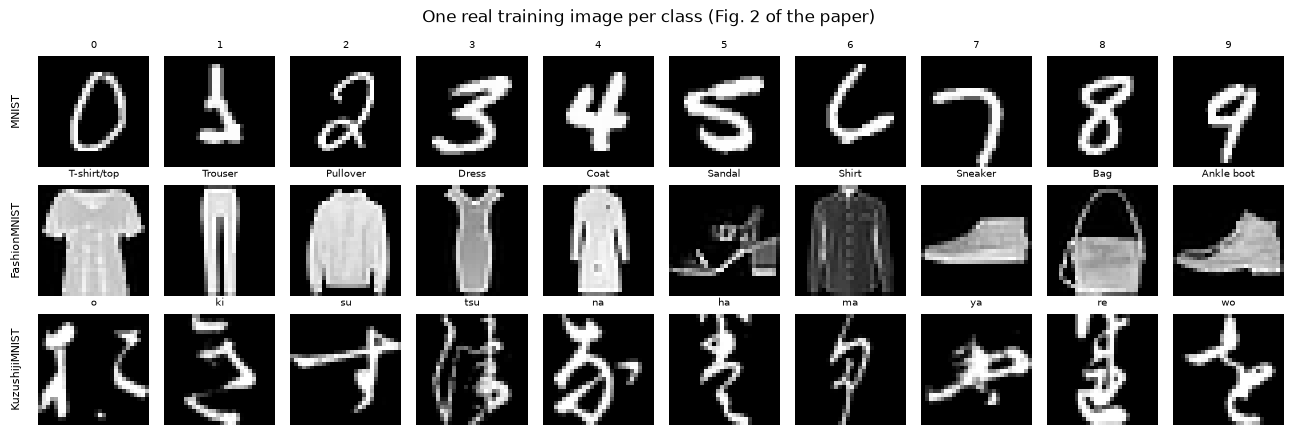

In [6]:
# ---- Dataset Exploration and Visualisation: the three real benchmarks, 10 classes, 100 images per class (paper setting) ----
from sklearn.decomposition import PCA
EXPLORE = {}
for ds in SPEC:
    Xtr, Xte, ytr, yte = make_dataset(ds, 10, SEED)
    EXPLORE[ds] = (Xtr, Xte, ytr, yte)
    names = SPEC[ds]["names"]
    print(f"=== {ds}: sampled {len(Xtr) + len(Xte)} images (100 per class) of shape 28x28 = 784 pixel features (pixel_r_c, scaled to [0,1]); "
          f"train {Xtr.shape}, test {Xte.shape}")
    print("    original label values and counts (train / test):",
          {f"{c}:{names[c]}": (int((ytr == c).sum()), int((yte == c).sum())) for c in range(10)})

# example images
fig, axs = plt.subplots(3, 10, figsize=(13, 4.4))
for r, ds in enumerate(SPEC):
    Xtr, _, ytr, _ = EXPLORE[ds]
    for c in range(10):
        ax = axs[r, c]; ax.imshow(Xtr[np.where(ytr == c)[0][0]].reshape(28, 28), cmap="gray"); ax.axis("off")
        ax.set_title(SPEC[ds]["names"][c], fontsize=7)
    axs[r, 0].text(-0.15, 0.5, ds, transform=axs[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
plt.suptitle("One real training image per class (Fig. 2 of the paper)"); plt.tight_layout(); plt.show()


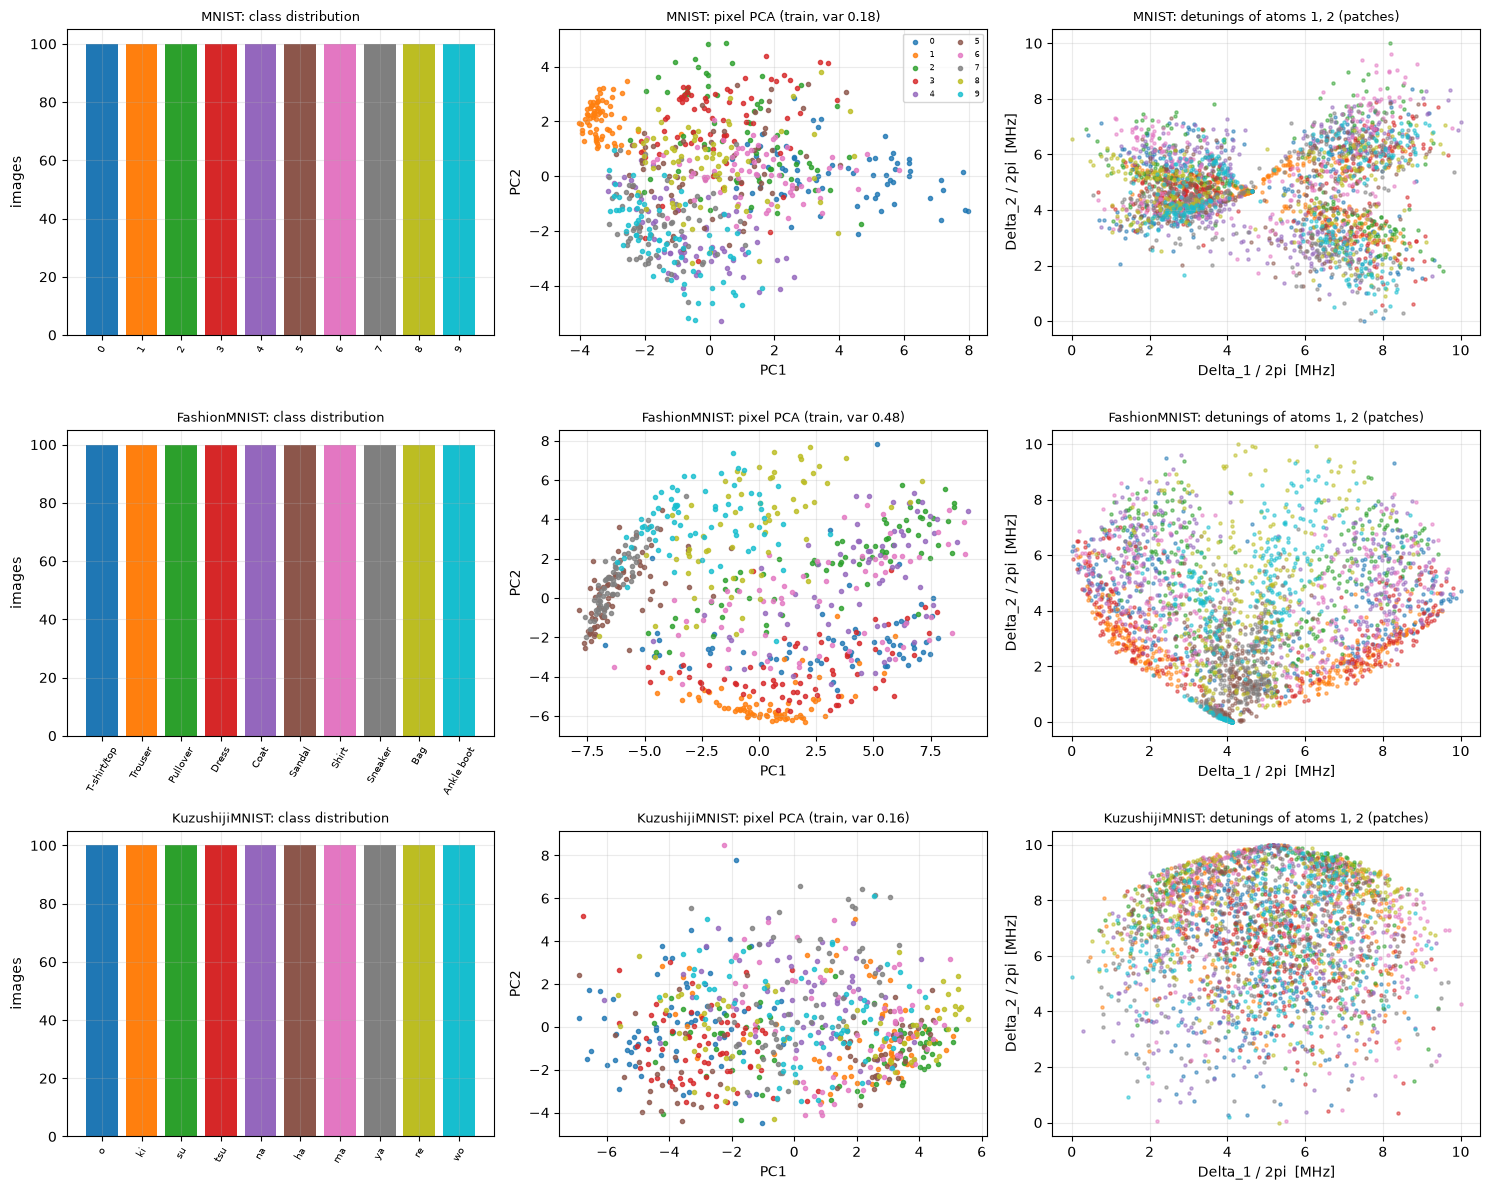

Each point is a real image (centre column) or a real 4x4 patch of a real image (right column); colour = ground-truth class. No synthetic data or invented labels are used anywhere in this notebook.


In [7]:
# class distribution + 2-D scatter of the real observations coloured by their ground-truth class
fig, axs = plt.subplots(3, 3, figsize=(15, 12))
cmap = plt.get_cmap("tab10")
for r, ds in enumerate(SPEC):
    Xtr, Xte, ytr, yte = EXPLORE[ds]; names = SPEC[ds]["names"]
    cnt = np.bincount(np.concatenate([ytr, yte]), minlength=10)
    axs[r, 0].bar(range(10), cnt, color=[cmap(c) for c in range(10)]); axs[r, 0].set_xticks(range(10)); axs[r, 0].set_xticklabels(names, rotation=60, fontsize=7)
    axs[r, 0].set_title(f"{ds}: class distribution", fontsize=9); axs[r, 0].set_ylabel("images")
    # (b) raw PCA of the 784-pixel images, fitted on the training split
    pca = PCA(2, random_state=SEED).fit(Xtr); Z = pca.transform(Xtr)
    for c in range(10): axs[r, 1].scatter(Z[ytr == c, 0], Z[ytr == c, 1], s=9, color=cmap(c), label=names[c], alpha=0.8)
    axs[r, 1].set_title(f"{ds}: pixel PCA (train, var {pca.explained_variance_ratio_.sum():.2f})", fontsize=9); axs[r, 1].set_xlabel("PC1"); axs[r, 1].set_ylabel("PC2")
    if r == 0: axs[r, 1].legend(fontsize=6, ncol=2)
    # (c) what the reservoir receives: the first two normalised patch-PCA features, mapped to detunings (Eqs. 3-6 and 5)
    pre = Preproc().fit(Xtr, 8); A = to_detuning(pre.a(Xtr)) / TWO_PI                       # detuning in MHz, (B, kappa, 8)
    for c in range(10):
        pts = A[ytr == c][:, :, :2].reshape(-1, 2); axs[r, 2].scatter(pts[:, 0], pts[:, 1], s=5, color=cmap(c), alpha=0.5)
    axs[r, 2].set_title(f"{ds}: detunings of atoms 1, 2 (patches)", fontsize=9)
    axs[r, 2].set_xlabel("Delta_1 / 2pi  [MHz]"); axs[r, 2].set_ylabel("Delta_2 / 2pi  [MHz]")
plt.tight_layout(); plt.show()
print("Each point is a real image (centre column) or a real 4x4 patch of a real image (right column); colour = ground-truth class. "
      "No synthetic data or invented labels are used anywhere in this notebook.")


## 3. The Rydberg reservoir, emulated exactly

For one sample the Hamiltonian (Eq. 18) is constant in time, `H = Omega/2 sum X_i - alpha sum Delta_i n_i + sum V_ij n_i n_j`, a real symmetric 2^N x 2^N matrix. We diagonalise it once,
`H = V E V^T`, and get `|psi(t)> = V exp(-iEt) V^T |+>^N` at all six read-out times. The features are the diagonal observables `<Z_i>` and `<Z_i Z_j>` (Eq. 21), 6 x (N + N(N-1)/2) numbers.
For the attacks we also need `dPhi/dDelta_i`; with `T_i = V^T n_i V` and the divided differences `K_ab(t) = (e^{-iE_b t} - e^{-iE_a t})/(E_a - E_b)` the state derivative in the eigenbasis is
`d c_a / d Delta_i = alpha sum_b T_i,ab K_ab c0_b`, which gives the exact Jacobian without automatic differentiation.


In [8]:
# ---- the Rydberg reservoir: exact evolution of H = sum_i Omega/2 X_i - sum_i alpha*Delta_i n_i + sum_{i<j} V_ij n_i n_j  (Eq. 18) ----
from itertools import combinations
class Reservoir:
    """N atoms on a line, qubit i = bit i of the basis index (little-endian, same as Qiskit). |g> = |0>, |r> = |1>, n_i = |r><r|.
       H is real symmetric and time-independent for a given sample, so U(t) = V exp(-iEt) V^T from one eigendecomposition.
       embed(): features Phi (Eq. 25) and, if jac=True, the exact Jacobian dPhi/dDelta (first-order perturbation theory in the eigenbasis)."""
    def __init__(self, n_atoms=8, d_um=None, C6_=None, omega=None, alpha=None, T=None, M=None):
        d_um = LATTICE_UM if d_um is None else d_um; C6_ = C6 if C6_ is None else C6_
        self.N = N = n_atoms; self.n = 2 ** N
        self.omega = OMEGA if omega is None else omega; self.alpha = ALPHA_LOC if alpha is None else alpha
        self.T = T_TOTAL if T is None else T; self.M = M_STEPS if M is None else M
        s = np.arange(self.n)
        self.occ = ((s[None, :] >> np.arange(N)[:, None]) & 1).astype(float)            # (N, n): n_i(s)
        pos = np.arange(N) * d_um
        self.pairs = list(combinations(range(N), 2))
        self.Vij = np.array([C6_ / abs(pos[i] - pos[j]) ** 6 for i, j in self.pairs])   # van der Waals, Eq. 18
        self.vdiag = sum((v * self.occ[i] * self.occ[j] for v, (i, j) in zip(self.Vij, self.pairs)), np.zeros(self.n))
        XS = np.zeros((self.n, self.n))
        for i in range(N): XS[s, s ^ (1 << i)] += 1.0                                     # sum_i sigma_x_i
        self.XS = XS
        z = 1 - 2 * self.occ                                                              # Z_i = |g><g| - |r><r|
        self.Zmat = np.vstack([z] + ([np.array([z[i] * z[j] for i, j in self.pairs])] if self.pairs else []))   # (R, n) Eq. 21
        self.R = self.Zmat.shape[0]; self.D = self.M * self.R                              # Eq. 9 / 25: D = M (N + N(N-1)/2)
        self.tm = np.arange(1, self.M + 1) * self.T / self.M                               # Eq. 22
        self.psi0 = np.full(self.n, 1 / np.sqrt(self.n))                                   # |+>^N
        self.half = [np.where(self.occ[i] > 0)[0] for i in range(N)]                       # states with atom i excited

    def hamiltonian(self, delta):
        d = self.vdiag[None, :] - self.alpha * (delta @ self.occ)
        H = np.broadcast_to(self.omega / 2 * self.XS, (delta.shape[0],) + self.XS.shape).copy()
        ii = np.arange(self.n); H[:, ii, ii] += d
        return H

    def embed(self, delta, jac=False):
        B, N, n, M = delta.shape[0], self.N, self.n, self.M
        E, V = np.linalg.eigh(self.hamiltonian(delta))                                      # (B,n), (B,n,n)
        c0 = np.einsum("bsa,s->ba", V, self.psi0)                                           # V^T psi0
        ang = E[:, None, :] * self.tm[None, :, None]                                        # (B,M,n)
        cr, ci = np.cos(ang) * c0[:, None, :], -np.sin(ang) * c0[:, None, :]                # c_a(t) = e^{-iE_a t} c0_a
        pr = np.matmul(V[:, None], cr[..., None])[..., 0]                                   # Re psi(t_m), (B,M,n)
        pi_ = np.matmul(V[:, None], ci[..., None])[..., 0]                                  # Im psi(t_m)
        prob = pr ** 2 + pi_ ** 2
        Phi = (prob @ self.Zmat.T).reshape(B, -1)                                           # time-major, Z_1..Z_N, Z_1Z_2.. (Eq. 25)
        if not jac: return Phi
        # exact Jacobian: d c_a/d Delta_i = alpha * sum_c T_i[a,c] K[a,c] c0_c  with T_i = V^T n_i V and divided differences K
        Ta = np.empty((B, n, N, n))                                                         # T_i stored as [b, a, i, c]
        for i, h in enumerate(self.half):
            Ta[:, :, i, :] = np.matmul(np.swapaxes(V[:, h, :], 1, 2), V[:, h, :])
        dE = E[:, :, None] - E[:, None, :]; small = np.abs(dE) < 1e-9; dEs = np.where(small, 1.0, dE)
        Vt = np.swapaxes(V, 1, 2); J = np.zeros((B, M, self.R, N))
        for m in range(M):
            t = self.tm[m]; fr, fi = np.cos(ang[:, m]), -np.sin(ang[:, m])                  # e^{-iE t} (B,n)
            Kr = (fr[:, None, :] - fr[:, :, None]) / dEs
            Ki = (fi[:, None, :] - fi[:, :, None]) / dEs
            # degenerate limit: K -> i t e^{-iEt} = t*sin(Et) + i t*cos(Et)
            Kr = np.where(small, t * (-fi)[:, :, None], Kr); Ki = np.where(small, t * fr[:, :, None], Ki)
            W = np.stack([Kr * c0[:, None, :], Ki * c0[:, None, :]], axis=-1)               # (B,a,c,2)
            dc = self.alpha * np.matmul(Ta, W)                                              # (B,a,N,2)
            dcr, dci = dc[..., 0].transpose(0, 2, 1), dc[..., 1].transpose(0, 2, 1)         # (B,N,a)
            dpr, dpi = np.matmul(dcr, Vt), np.matmul(dci, Vt)                               # d psi = V dc, (B,N,s)
            g = pr[:, m, None, :] * dpr + pi_[:, m, None, :] * dpi
            J[:, m] = 2 * np.matmul(g, self.Zmat.T).transpose(0, 2, 1)                      # (B,R,N)
        return Phi, J.reshape(B, M * self.R, N)

_RES_CACHE = {}
def get_reservoir(n_atoms, **kw):
    key = (n_atoms, tuple(sorted(kw.items())))
    if key not in _RES_CACHE: _RES_CACHE[key] = Reservoir(n_atoms, **{("C6_" if k == "C6" else k): v for k, v in kw.items()})
    return _RES_CACHE[key]


### 3.1 Validation: independent evolution and finite differences
`scipy.linalg.expm(-iHt)` (a Pade scaling-and-squaring algorithm, nothing in common with our eigen-decomposition) must reproduce the embedding, and central finite differences must reproduce the Jacobian.


In [9]:
# ---- independent checks of the reservoir emulation ----
# (1) states against scipy's matrix exponential expm(-iHt)|psi0>  (a different algorithm from our eigendecomposition)
# (2) the analytic Jacobian against central finite differences
chk_rng = np.random.default_rng(SEED)
rows = []
for N in (2, 4, 6, 8):
    res = get_reservoir(N)
    dl = chk_rng.uniform(DELTA_MIN, DELTA_MAX, size=(3, N))
    Phi, Jac = res.embed(dl, jac=True)
    H = res.hamiltonian(dl)
    ref = np.array([np.concatenate([res.Zmat @ np.abs(expm(-1j * H[b] * t) @ res.psi0) ** 2 for t in res.tm]) for b in range(3)])
    h = 1e-5; Jfd = np.zeros_like(Jac)
    for i in range(N):
        up = dl.copy(); up[:, i] += h; dn = dl.copy(); dn[:, i] -= h
        Jfd[:, :, i] = (res.embed(up) - res.embed(dn)) / (2 * h)
    rows.append(dict(atoms=N, hilbert_dim=res.n, embedding_dim_D=res.D, max_err_vs_expm=np.abs(ref - Phi).max(),
                     max_err_jacobian=np.abs(Jac - Jfd).max(), jacobian_scale=np.abs(Jac).max()))
    assert np.abs(ref - Phi).max() < 1e-10 and np.abs(Jac - Jfd).max() < 1e-6 * max(1.0, np.abs(Jac).max()) + 1e-7
display(pd.DataFrame(rows).style.format({"max_err_vs_expm": "{:.1e}", "max_err_jacobian": "{:.1e}", "jacobian_scale": "{:.3f}"}))
print("embedding dimension check D = M*(N + N(N-1)/2):", [(r['atoms'], r['embedding_dim_D']) for r in rows])


,atoms,hilbert_dim,embedding_dim_D,max_err_vs_expm,max_err_jacobian,jacobian_scale
0,2,4,18,7.0e-15,3.3e-10,0.023
1,4,16,60,2.3e-14,1.8e-09,0.022
2,6,64,126,2.1e-14,2.5e-09,0.022
3,8,256,216,3.4e-14,3.3e-09,0.023


embedding dimension check D = M*(N + N(N-1)/2): [(2, 18), (4, 60), (6, 126), (8, 216)]


### 3.2 What the paper's constants mean physically
Table 1 lists `C6 = 2pi x 2000 MHz um^6` and a spacing of 10 um, which makes `V_nn = C6/d^6 = 2pi x 0.002 MHz`, three orders of magnitude below the Rabi frequency of 2pi x 5 MHz;
the Rydberg blockade radius `(C6/Omega)^(1/6)` is only 2.7 um. Real rubidium Rydberg atoms have `C6` of order `2pi x 10^6 MHz um^6`. The check below compares the connected correlations
`<Z_i Z_j> - <Z_i><Z_j>` (zero for a product state, i.e. for a reservoir without entanglement) for the paper's constants, for no interaction, and for a physical C6.


nearest-neighbour interaction V_nn = C6/d^6 = 2pi x 0.0020 MHz = 0.0126 rad/us
Rabi frequency Omega = 2pi x 5.0 MHz = 31.42 rad/us; Rydberg blockade radius (C6/Omega)^(1/6) = 2.71 um (lattice spacing 10.0 um)
=> V_nn / Omega = 4.0e-04 and V_nn * T = 0.038 rad: with the paper's own constants the atoms barely interact.


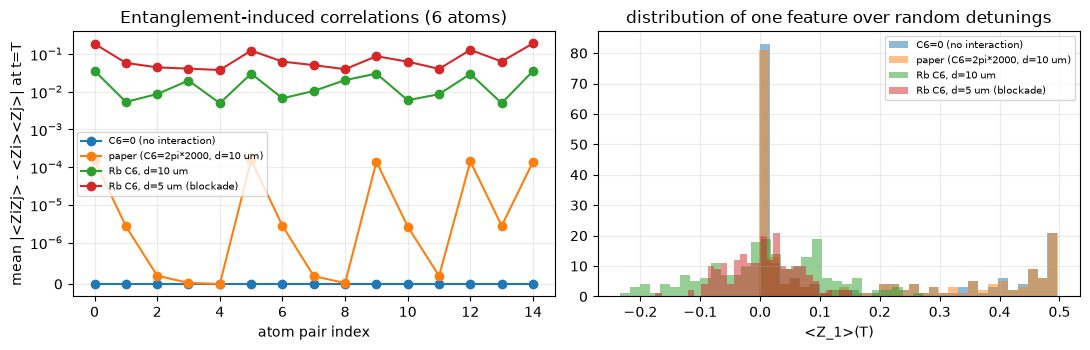

In [10]:
# ---- what does the paper's Table 1 imply physically? ----
res8 = get_reservoir(8)
Vnn = C6 / LATTICE_UM ** 6
r_block = (C6 / OMEGA) ** (1 / 6)
print(f"nearest-neighbour interaction V_nn = C6/d^6 = 2pi x {Vnn / TWO_PI:.4f} MHz = {Vnn:.4f} rad/us")
print(f"Rabi frequency Omega = 2pi x {OMEGA / TWO_PI:.1f} MHz = {OMEGA:.2f} rad/us; Rydberg blockade radius (C6/Omega)^(1/6) = {r_block:.2f} um (lattice spacing {LATTICE_UM} um)")
print(f"=> V_nn / Omega = {Vnn / OMEGA:.1e} and V_nn * T = {Vnn * T_TOTAL:.3f} rad: with the paper's own constants the atoms barely interact.")

# connected correlation <ZiZj> - <Zi><Zj> for random detunings, with the paper's C6, with no interaction, and with a physical Rb C6 at two spacings
C6_RB = TWO_PI * 862690.0      # CHOICE: C6 of Rb-87 |70S> as used on QuEra Aquila (2*pi*862690 MHz um^6)
variants = {"C6=0 (no interaction)": dict(C6=0.0), "paper (C6=2pi*2000, d=10 um)": dict(),
            "Rb C6, d=10 um": dict(C6=C6_RB), "Rb C6, d=5 um (blockade)": dict(C6=C6_RB, d_um=5.0)}
dl = np.random.default_rng(SEED).uniform(DELTA_MIN, DELTA_MAX, size=(200, 6))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for name, kw in variants.items():
    r = get_reservoir(6, **kw); Phi = r.embed(dl).reshape(len(dl), r.M, r.R)
    z = Phi[:, -1, :6]; zz = Phi[:, -1, 6:]
    conn = np.abs(zz - np.array([z[:, i] * z[:, j] for i, j in r.pairs]).T).mean(0)
    ax[0].plot(range(len(r.pairs)), conn, marker="o", label=name)
    ax[1].hist(Phi[:, -1, 0], bins=30, alpha=0.5, label=name)
ax[0].set_yscale("symlog", linthresh=1e-6); ax[0].set_xlabel("atom pair index"); ax[0].set_ylabel("mean |<ZiZj> - <Zi><Zj>| at t=T")
ax[0].set_title("Entanglement-induced correlations (6 atoms)"); ax[0].legend(fontsize=7)
ax[1].set_xlabel("<Z_1>(T)"); ax[1].set_title("distribution of one feature over random detunings"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()


## Quantum Circuit Architecture

The paper's reservoir is an *analogue* device: the laser pulses of a neutral-atom machine implement the Hamiltonian directly and there is no gate circuit. To make the quantum part executable on a
gate-based simulator we use the standard digital analogue, a second-order (Strang) Trotter circuit, and we **run it**. With `A = (Omega/2) sum_i X_i` and the diagonal part `B`
(written with `n_i = (1 - Z_i)/2`: `h_i Z_i` with `h_i = alpha Delta_i/2 - sum_j V_ij/4`, and `J_ij Z_i Z_j` with `J_ij = V_ij/4`), one step of length `dt` is
`exp(-iA dt/2) exp(-iB dt) exp(-iA dt/2)`, i.e. `RX(Omega dt/2)` on every qubit, `RZ(2 h_i dt)` on every qubit, `RZZ(2 J_ij dt)` on every pair, `RX(Omega dt/2)` again. The state `|+>^N` is prepared with Hadamards.
For the read-out time `t_m` the executed circuit `C_m` is `H^N` followed by `m x r` Strang steps (`r` steps per 0.5 us interval). Assumptions where the paper is silent: all 28 pairs of the 8-atom chain
interact with `V_ij = C6/|i-j|^6 d^-6` (not only neighbours); the global phase is dropped; atoms `|g>` = qubit state 0 and `|r>` = state 1. The reservoir has no trainable parameters; the only trainable parameters are in the classical MLP.
The 8-qubit circuit (256 amplitudes) is simulated with Qiskit's `Statevector`, and its embedding must converge to the exact evolution as `r` grows.


In [11]:
# ---- the Trotterised circuit that is executed (Qiskit) and its error against the exact evolution ----
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

def trotter_circuit(res, delta_row, m_snap, r_steps):
    """Circuit for U(t_m)|+>^N with second-order (Strang) Trotter steps, r_steps per read-out interval.
       exp(-i Omega/2 X dt) = RX(Omega dt); n_i = (1-Z_i)/2 gives h_i Z_i with h_i = alpha*Delta_i/2 - sum_j V_ij/4 and J_ij Z_i Z_j with J_ij = V_ij/4:
       exp(-i h Z dt) = RZ(2 h dt), exp(-i J ZZ dt) = RZZ(2 J dt)."""
    N = res.N; qc = QuantumCircuit(N, name=f"t{m_snap}")
    h = res.alpha * np.asarray(delta_row) / 2
    for v, (i, j) in zip(res.Vij, res.pairs): h[i] -= v / 4; h[j] -= v / 4
    dt = res.T / res.M / r_steps
    qc.h(range(N)); qc.barrier()                                                 # |+>^N
    n_steps = m_snap * r_steps
    for q in range(N): qc.rx(res.omega * dt / 2, q)                              # first half step of the Rabi drive
    for k in range(n_steps):
        for q in range(N): qc.rz(2 * h[q] * dt, q)                               # detuning (+ interaction single-site part)
        for v, (i, j) in zip(res.Vij, res.pairs): qc.rzz(2 * (v / 4) * dt, i, j) # van der Waals ZZ part
        for q in range(N): qc.rx(res.omega * dt * (1.0 if k < n_steps - 1 else 0.5), q)   # two half steps of neighbouring Strang steps merged
        qc.barrier()
    return qc

def circuit_embedding(res, delta_row, r_steps):
    """Run the M circuits C_1..C_M on the state-vector simulator and return Phi (Eq. 25)."""
    out = []
    for m in range(1, res.M + 1):
        p = Statevector(trotter_circuit(res, delta_row, m, r_steps)).probabilities()    # qiskit index == our basis index
        out.append(res.Zmat @ p)
    return np.concatenate(out)

res8 = get_reservoir(8)
test_rows = np.random.default_rng(SEED).uniform(DELTA_MIN, DELTA_MAX, size=(2, 8))
exact = res8.embed(test_rows)
err_rows = []
for r_steps in (1, 2, 4, 8, 16, 32):
    t0 = time.time()
    errs = [np.abs(circuit_embedding(res8, test_rows[b], r_steps) - exact[b]).max() for b in range(len(test_rows))]
    qc_last = trotter_circuit(res8, test_rows[0], res8.M, r_steps)
    err_rows.append(dict(trotter_steps_per_interval=r_steps, max_abs_error=max(errs), depth_of_C_M=qc_last.decompose().depth(),
                         gates_in_C_M=sum(qc_last.count_ops().get(g, 0) for g in ("rx", "rz", "rzz", "h")), seconds=time.time() - t0))
display(pd.DataFrame(err_rows).style.format({"max_abs_error": "{:.2e}", "seconds": "{:.1f}"}))
ers = [r["max_abs_error"] for r in err_rows]
assert all(a > b for a, b in zip(ers[:-1], ers[1:])) and ers[-1] < 5e-2        # monotone convergence to the exact evolution
print(f"Trotter error against the exact evolution (max |Phi_circuit - Phi_exact| over 2 random 8-atom samples) falls from "
      f"{ers[0]:.2f} ({err_rows[0]['trotter_steps_per_interval']} Strang step per 0.5 us) to {ers[-1]:.1e} ({err_rows[-1]['trotter_steps_per_interval']} steps); the last two ratios {ers[-3] / ers[-2]:.1f}, {ers[-2] / ers[-1]:.1f} "
      f"approach 4 as expected for a second-order formula. Note Omega*dt = 15.7/r rad per interval: the 5 MHz Rabi drive needs many steps.")


,trotter_steps_per_interval,max_abs_error,depth_of_C_M,gates_in_C_M,seconds
0,1,1.48e+00,248,280,1.0
1,2,1.22e+00,494,544,1.4
2,4,5.22e-01,986,1072,2.1
3,8,2.36e-01,1970,2128,6.2
4,16,7.10e-02,3938,4240,10.3
5,32,1.91e-02,7874,8464,23.5


Trotter error against the exact evolution (max |Phi_circuit - Phi_exact| over 2 random 8-atom samples) falls from 1.48 (1 Strang step per 0.5 us) to 1.9e-02 (32 steps); the last two ratios 3.3, 3.7 approach 4 as expected for a second-order formula. Note Omega*dt = 15.7/r rad per interval: the 5 MHz Rabi drive needs many steps.


### The executed circuit
`C_1` for the 8-atom reservoir of Table 1 with one Strang step for the first 0.5 us (a random-detuning sample); `C_2 ... C_6` append the same block (one `RZ` layer, the 28 `RZZ` gates, one `RX` layer). The tiny `RZZ` angles are the van der Waals couplings of the paper's constants (section 3.2). Rows of the error table above use 1 to 32 steps.


qubits = 8 | depth = 17 (decomposed 43) | gate counts = {'rzz': 28, 'rx': 16, 'h': 8, 'rz': 8, 'barrier': 2}
trainable parameters in the reservoir circuit = 0 (the reservoir is fixed); data-dependent angles = 8 RZ angles per step (from the 8 detunings); trainable parameters of the classical read-out are counted in the MLP section
full executed circuits C_m = H^N followed by m * r Strang steps (r = 1 here); depth of C_1..C_6 = [17, 32, 47, 62, 77, 92]


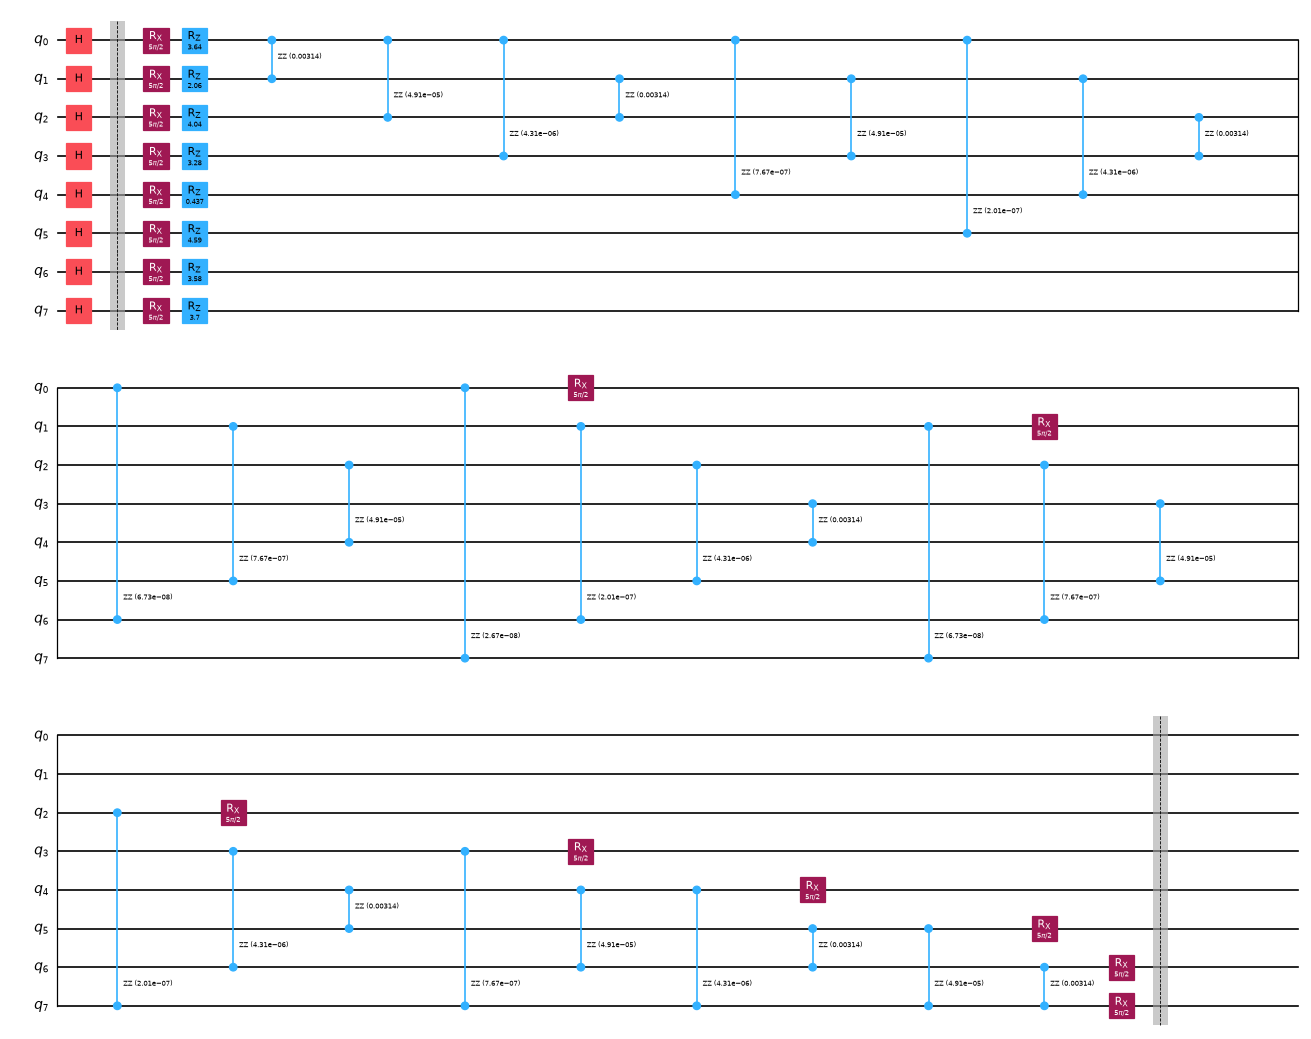

In [12]:
# ---- draw the circuit that was executed: C_1 (first read-out time, one Strang step) for the 8-atom reservoir of Table 1 ----
qc_draw = trotter_circuit(res8, test_rows[0], 1, 1)
print(f"qubits = {qc_draw.num_qubits} | depth = {qc_draw.depth()} (decomposed {qc_draw.decompose().depth()}) | gate counts = {dict(qc_draw.count_ops())}")
print(f"trainable parameters in the reservoir circuit = 0 (the reservoir is fixed); data-dependent angles = {res8.N} RZ angles per step (from the 8 detunings);"
      f" trainable parameters of the classical read-out are counted in the MLP section")
print("full executed circuits C_m = H^N followed by m * r Strang steps (r = 1 here); depth of C_1..C_6 =",
      [trotter_circuit(res8, test_rows[0], m, 1).depth() for m in range(1, res8.M + 1)])
fig = qc_draw.draw("mpl", fold=32, scale=0.6, style="iqp")
display(fig)


## 4. The classical read-out and the models being compared

`mlp_*` implements the paper's D-64-32-C network with ReLU and dropout 1e-3, trained with Adam (lr 1e-3, batch 64) on softmax cross-entropy, entirely in NumPy so that the input gradient
needed for the attacks is available in closed form (`mlp_input_jacobian`). A model is a frozen feature map, a standardisation fitted on the training features, and an MLP:

| Model | Feature map (all start from the same training-split PCA patches) | Features |
|---|---|---|
| **QRC+MLP** | Rydberg reservoir, patch-averaged (Eq. 10) | D = 6 (N + N(N-1)/2) |
| MLP (PCA mean) | patch-average of the N normalised PCA components: the reservoir's *input* with no reservoir | N |
| MLP (PCA patches) | all 4 x N normalised PCA components | 4 N |
| Random tanh reservoir+MLP | per-patch random `tanh(A a + b)` features, same D, patch-averaged | D |
| MLP (64 pixels) | the 8 x 8 down-sampled pixels | 64 |


In [13]:
# ---- the classical read-out: MLP D-64-32-C with ReLU, dropout 1e-3, Adam (lr 1e-3, batch 64), cross-entropy; manual back-propagation ----
def softmax(z):
    e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def mlp_init(D, C, rng):
    sizes = [D, H1, H2, C]
    return [[rng.normal(0, np.sqrt(2 / a), (a, b)), np.zeros(b)] for a, b in zip(sizes[:-1], sizes[1:])]

def mlp_forward(P, F, drop=0.0, rng=None):
    h1p = F @ P[0][0] + P[0][1]; h1 = np.maximum(h1p, 0)
    m1 = (rng.random(h1.shape) >= drop) / (1 - drop) if drop > 0 else 1.0
    h1d = h1 * m1
    h2p = h1d @ P[1][0] + P[1][1]; h2 = np.maximum(h2p, 0)
    m2 = (rng.random(h2.shape) >= drop) / (1 - drop) if drop > 0 else 1.0
    h2d = h2 * m2
    return h2d @ P[2][0] + P[2][1], (F, h1p, m1, h1d, h2p, m2, h2d)

def mlp_backward(P, cache, dlog):
    F, h1p, m1, h1d, h2p, m2, h2d = cache
    g3 = [h2d.T @ dlog, dlog.sum(0)]
    d = (dlog @ P[2][0].T) * m2 * (h2p > 0)
    g2 = [h1d.T @ d, d.sum(0)]
    d = (d @ P[1][0].T) * m1 * (h1p > 0)
    g1 = [F.T @ d, d.sum(0)]
    return [g1, g2, g3]

def mlp_input_jacobian(P, F):
    """d logits / d input for every class: (B, C, D). Inference mode (no dropout)."""
    a1 = ((F @ P[0][0] + P[0][1]) > 0).astype(float)
    a2 = ((np.maximum(F @ P[0][0] + P[0][1], 0) @ P[1][0] + P[1][1]) > 0).astype(float)
    A2 = P[2][0].T[None] * a2[:, None, :]                 # (B, C, H2)
    A1 = (A2 @ P[1][0].T) * a1[:, None, :]                # (B, C, H1)
    return A1 @ P[0][0].T                                 # (B, C, D)

def train_mlp(Ftr, ytr, C, epochs, rng):
    P = mlp_init(Ftr.shape[1], C, rng)
    m = [[np.zeros_like(w), np.zeros_like(b)] for w, b in P]; v = [[np.zeros_like(w), np.zeros_like(b)] for w, b in P]
    t = 0; Y = np.eye(C)[ytr]; n = len(Ftr)
    for ep in range(epochs):
        perm = rng.permutation(n)
        for s in range(0, n, BATCH):
            ib = perm[s:s + BATCH]
            lg, cache = mlp_forward(P, Ftr[ib], DROPOUT, rng)
            grads = mlp_backward(P, cache, (softmax(lg) - Y[ib]) / len(ib))
            t += 1
            for L in range(3):
                for k in range(2):
                    g = grads[L][k]
                    m[L][k] = 0.9 * m[L][k] + 0.1 * g; v[L][k] = 0.999 * v[L][k] + 0.001 * g * g
                    P[L][k] -= LR * (m[L][k] / (1 - 0.9 ** t)) / (np.sqrt(v[L][k] / (1 - 0.999 ** t)) + 1e-8)
    return P

def n_params(P): return sum(w.size + b.size for w, b in P)
print("MLP readout parameters for D=216 (8 atoms), 10 classes:", n_params(mlp_init(216, 10, np.random.default_rng(0))))


MLP readout parameters for D=216 (8 atoms), 10 classes: 16298


In [14]:
# ---- the five models: QRC + MLP and four classical references, all fed by the SAME pre-processed patches ----
class QRCFeatures:
    name = "QRC+MLP"
    def __init__(self, pre, res): self.pre, self.res = pre, res
    def f(self, X):
        B = len(X); a = self.pre.a(X); d = to_detuning(a).reshape(-1, self.res.N)
        Phi = np.concatenate([self.res.embed(d[i:i + 64]) for i in range(0, len(d), 64)])
        return Phi.reshape(B, self.pre.kappa, -1).mean(1)                               # Eq. 10: patch average
    def fj(self, X):
        B, k = len(X), self.pre.kappa; a = self.pre.a(X); d = to_detuning(a).reshape(-1, self.res.N)
        Ph, Jr = [], []
        for i in range(0, len(d), 16):
            p, j = self.res.embed(d[i:i + 16], jac=True); Ph.append(p); Jr.append(j)
        Ph = np.concatenate(Ph).reshape(B, k, -1); Jr = np.concatenate(Jr).reshape(B, k, self.res.D, self.res.N)
        dDelta_dx = (DELTA_MAX - DELTA_MIN) * self.pre.Gs                               # (kappa, N, 784)
        return Ph.mean(1), np.einsum("bkdn,knx->bdx", Jr, dDelta_dx) / k

class PCAMeanFeatures:
    name = "MLP (PCA mean)"
    def __init__(self, pre): self.pre = pre
    def f(self, X): return self.pre.a(X).mean(1)
    def fj(self, X): return self.f(X), np.broadcast_to(self.pre.Gs.mean(0), (len(X),) + self.pre.Gs.shape[1:])

class PCAConcatFeatures:
    name = "MLP (PCA patches)"
    def __init__(self, pre): self.pre = pre
    def f(self, X): return self.pre.a(X).reshape(len(X), -1)
    def fj(self, X): return self.f(X), np.broadcast_to(self.pre.Gs.reshape(-1, 784), (len(X), self.pre.kappa * self.pre.delta, 784))

class RandomReservoirFeatures:
    """CHOICE: classical control with the same output size D as the quantum reservoir: per-patch random tanh features, patch mean."""
    name = "Random tanh reservoir+MLP"
    def __init__(self, pre, D, rng, scale=1.0):
        self.pre = pre; self.A = rng.normal(0, scale, (pre.delta, D)); self.b = rng.uniform(-1, 1, D)
    def f(self, X): return np.tanh((self.pre.a(X) - 0.5) @ self.A + self.b).mean(1)
    def fj(self, X):
        a = self.pre.a(X); u = np.tanh((a - 0.5) @ self.A + self.b)                      # (B, kappa, D)
        dtanh = 1 - u ** 2
        J = np.einsum("bkd,nd,knx->bdx", dtanh, self.A, self.pre.Gs) / self.pre.kappa
        return u.mean(1), J

class PixelFeatures:
    name = "MLP (64 pixels)"
    def __init__(self, pre): self.pre = pre
    def f(self, X): return X @ self.pre.L.T
    def fj(self, X): return self.f(X), np.broadcast_to(self.pre.L, (len(X),) + self.pre.L.shape)

class Classifier:
    """Frozen feature map + standardisation (training statistics) + trained MLP, with exact input gradients for white-box attacks."""
    def __init__(self, fm, Xtr, ytr, C, epochs, seed):
        self.fm, self.C = fm, C
        t0 = time.time(); Ftr = fm.f(Xtr); self.t_feat = time.time() - t0
        sd0 = Ftr.std(0)
        # CHOICE: floor the scale of (almost) constant features, e.g. the always-black corner pixels, at 10 % of the median scale; otherwise a 0.01 change of such a
        # feature is amplified by 1e8 and every model would 'break' for an artificial reason
        self.mu, self.sd = Ftr.mean(0), np.maximum(sd0, 0.1 * np.median(sd0)) + 1e-12   # fitted on the training split only
        self.P = train_mlp((Ftr - self.mu) / self.sd, ytr, C, epochs, np.random.default_rng(seed))
        self.D = Ftr.shape[1]
    def logits(self, X):
        return mlp_forward(self.P, (self.fm.f(X) - self.mu) / self.sd)[0]
    def predict(self, X): return self.logits(X).argmax(1)
    def logits_jac(self, X, chunk=8):
        L, J = [], []
        for i in range(0, len(X), chunk):
            F, JF = self.fm.fj(X[i:i + chunk]); Fs = (F - self.mu) / self.sd
            L.append(mlp_forward(self.P, Fs)[0])
            J.append(np.einsum("bcd,bdx->bcx", mlp_input_jacobian(self.P, Fs), JF / self.sd[None, :, None]))
        return np.concatenate(L), np.concatenate(J)
    def grad_ce(self, X, y):
        lg, J = self.logits_jac(X)
        return np.einsum("bc,bcx->bx", softmax(lg) - np.eye(self.C)[y], J)


## 5. White-box attacks through the quantum reservoir

Gradients with respect to the *pixels* flow through the MLP, the standardisation, the patch average, the exact reservoir Jacobian, the min-max map, the PCA projection and the area-interpolation matrix.
Each model is attacked with its own gradients (white box). FGSM and PGD are L-infinity attacks with budget eps (clipped to the pixel box); DeepFool finds the smallest L2 perturbation that flips the prediction and
is then rescaled to the budget (Eq. 14). Budgets: eps in {0, 0.01, 0.04, 0.07, 0.10}, the tick values of the paper's figures.


In [15]:
# ---- white-box attacks on the pixels (Eqs. 11-14), model gradients are exact ----
def fgsm_all(model, X, y, eps_list):
    g = np.sign(np.concatenate([model.grad_ce(X[i:i + 8], y[i:i + 8]) for i in range(0, len(X), 8)]))   # direction does not depend on eps
    return {e: np.clip(X + e * g, 0, 1) for e in eps_list}

def pgd(model, X, y, eps, steps, rng):
    if eps == 0: return X.copy()
    step = PGD_STEP_FACTOR * eps / steps                         # CHOICE (paper: 100 steps of size 1e-3)
    Xa = np.clip(X + rng.uniform(-eps, eps, X.shape), 0, 1)       # random start inside the ball
    for _ in range(steps):
        g = np.concatenate([model.grad_ce(Xa[i:i + 8], y[i:i + 8]) for i in range(0, len(X), 8)])
        Xa = np.clip(np.clip(Xa + step * np.sign(g), X - eps, X + eps), 0, 1)
    return Xa

def deepfool(model, X, max_iter, overshoot=DEEPFOOL_OVERSHOOT):
    """Minimal L2 perturbation eta* that flips the prediction (multi-class DeepFool, Eq. 13); returned unscaled."""
    n = len(X); k0 = model.predict(X); r_tot = np.zeros_like(X); active = np.ones(n, bool)
    for _ in range(max_iter):
        idx = np.where(active)[0]
        if len(idx) == 0: break
        lg, J = model.logits_jac(np.clip(X[idx] + (1 + overshoot) * r_tot[idx], 0, 1))
        flipped = lg.argmax(1) != k0[idx]; active[idx[flipped]] = False
        idx, lg, J = idx[~flipped], lg[~flipped], J[~flipped]
        if len(idx) == 0: break
        k = k0[idx]; ar = np.arange(len(idx))
        w = J - J[ar, k][:, None, :]; f = lg - lg[ar, k][:, None]
        nrm = np.linalg.norm(w, axis=2) + 1e-12
        pert = np.abs(f) / nrm; pert[ar, k] = np.inf
        l = pert.argmin(1)
        r_tot[idx] += (pert[ar, l] + 1e-4)[:, None] * w[ar, l] / nrm[ar, l][:, None]
    return (1 + overshoot) * r_tot

def deepfool_budget(X, eta, eps):
    """Eq. 14: rescale to the L2 budget eps if necessary, then clip to the image box."""
    nrm = np.linalg.norm(eta, axis=1, keepdims=True) + 1e-12
    return np.clip(X + np.minimum(1.0, eps / nrm) * eta, 0, 1)

ATTACKS = ("FGSM", "PGD", "DeepFool (L2<=eps)", "DeepFool (L2<=28*eps)")
# NOTE: eps <= 0.1 in L2 on a 784-pixel image is a perturbation of ~0.004 per pixel, i.e. almost nothing; the L-infinity budgets of FGSM/PGD
# correspond to an L2 norm of up to 28*eps. We therefore also report DeepFool with the RMS-matched budget 28*eps (CHOICE; the paper does not say).

def attack_curves(models, Xs, ys, attacks, seed):
    """accuracy of every model under every attack (each model is attacked with its own gradients) for eps in EPS_GRID."""
    out = {a: {} for a in attacks}; rng = np.random.default_rng(seed + 1)
    for name, mod in models.items():
        t0 = time.time()
        if "FGSM" in attacks:
            adv = fgsm_all(mod, Xs, ys, EPS_GRID)
            out["FGSM"][name] = [float((mod.predict(adv[e]) == ys).mean()) for e in EPS_GRID]
        if "PGD" in attacks:
            out["PGD"][name] = [float((mod.predict(pgd(mod, Xs, ys, e, PGD_STEPS, rng)) == ys).mean()) for e in EPS_GRID]
        if any(a.startswith("DeepFool") for a in attacks):
            eta = deepfool(mod, Xs, DEEPFOOL_ITERS)
            for a, mult in (("DeepFool (L2<=eps)", 1.0), ("DeepFool (L2<=28*eps)", 28.0)):
                if a in attacks:
                    out[a][name] = [float((mod.predict(deepfool_budget(Xs, eta, e * mult)) == ys).mean()) for e in EPS_GRID]
        print(f"    attacked {name:28s} in {time.time() - t0:6.1f} s")
    return out


In [16]:
# ---- one experimental configuration: dataset, atoms (= PCA dims), classes, seed ----
MODEL_ORDER = ["QRC+MLP", "MLP (PCA mean)", "MLP (PCA patches)", "Random tanh reservoir+MLP", "MLP (64 pixels)"]
RESULTS = {}

def run_config(ds, atoms, classes, seed, attack=True, models_wanted=MODEL_ORDER, res_kw=None, attacks=ATTACKS, tag="paper"):
    key = (ds, atoms, classes, seed, tag)
    if key in RESULTS: return RESULTS[key]
    t0 = time.time()
    Xtr, Xte, ytr, yte = make_dataset(ds, classes, seed)
    pre = Preproc().fit(Xtr, atoms)
    res = get_reservoir(atoms, **(res_kw or {}))
    fmaps = {"QRC+MLP": QRCFeatures(pre, res), "MLP (PCA mean)": PCAMeanFeatures(pre), "MLP (PCA patches)": PCAConcatFeatures(pre),
             "Random tanh reservoir+MLP": RandomReservoirFeatures(pre, res.D, np.random.default_rng(seed + 7)), "MLP (64 pixels)": PixelFeatures(pre)}
    models = {n: Classifier(fmaps[n], Xtr, ytr, classes, EPOCHS, seed) for n in models_wanted}
    clean = {n: float((m.predict(Xte) == yte).mean()) for n, m in models.items()}
    train_acc = {n: float((m.predict(Xtr) == ytr).mean()) for n, m in models.items()}
    out = dict(clean=clean, train_acc=train_acc, n_train=len(Xtr), n_test=len(Xte), D=res.D, adv=None, n_attack=0)
    print(f"[{ds} atoms={atoms} classes={classes} seed={seed} {tag}] clean test acc: " + ", ".join(f"{k}={v:.3f}" for k, v in clean.items()) +
          f"  ({time.time() - t0:.0f} s)")
    if attack:
        na = min(ATTACK_MAX.get(atoms, 40), len(Xte))
        sel = np.random.default_rng(seed + 3).choice(len(Xte), na, replace=False)
        out["n_attack"] = na
        out["adv"] = attack_curves(models, Xte[sel], yte[sel], attacks, seed)
        print(f"    attack set: {na} test images; total {time.time() - t0:.0f} s")
    RESULTS[key] = out
    return out


## 6. Experiments

### 6.1 Clean accuracy versus atoms and classes (Fig. 1b)


[MNIST atoms=2 classes=2 seed=42 grid] clean test acc: QRC+MLP=0.983, MLP (PCA mean)=0.983  (8 s)


[MNIST atoms=2 classes=4 seed=42 grid] clean test acc: QRC+MLP=0.808, MLP (PCA mean)=0.658  (13 s)


[MNIST atoms=2 classes=6 seed=42 grid] clean test acc: QRC+MLP=0.694, MLP (PCA mean)=0.400  (15 s)


[MNIST atoms=2 classes=8 seed=42 grid] clean test acc: QRC+MLP=0.646, MLP (PCA mean)=0.383  (26 s)


[MNIST atoms=2 classes=10 seed=42 grid] clean test acc: QRC+MLP=0.507, MLP (PCA mean)=0.303  (36 s)


...

[MNIST atoms=6 classes=6 seed=42 grid] clean test acc: QRC+MLP=0.883, MLP (PCA mean)=0.750  (30 s)


[MNIST atoms=6 classes=8 seed=42 grid] clean test acc: QRC+MLP=0.858, MLP (PCA mean)=0.696  (40 s)


[MNIST atoms=6 classes=10 seed=42 grid] clean test acc: QRC+MLP=0.773, MLP (PCA mean)=0.620  (67 s)


[MNIST atoms=8 classes=2 seed=42 grid] clean test acc: QRC+MLP=1.000, MLP (PCA mean)=1.000  (184 s)


[MNIST atoms=8 classes=4 seed=42 grid] clean test acc: QRC+MLP=0.942, MLP (PCA mean)=0.900  (344 s)
grid finished in 914 s


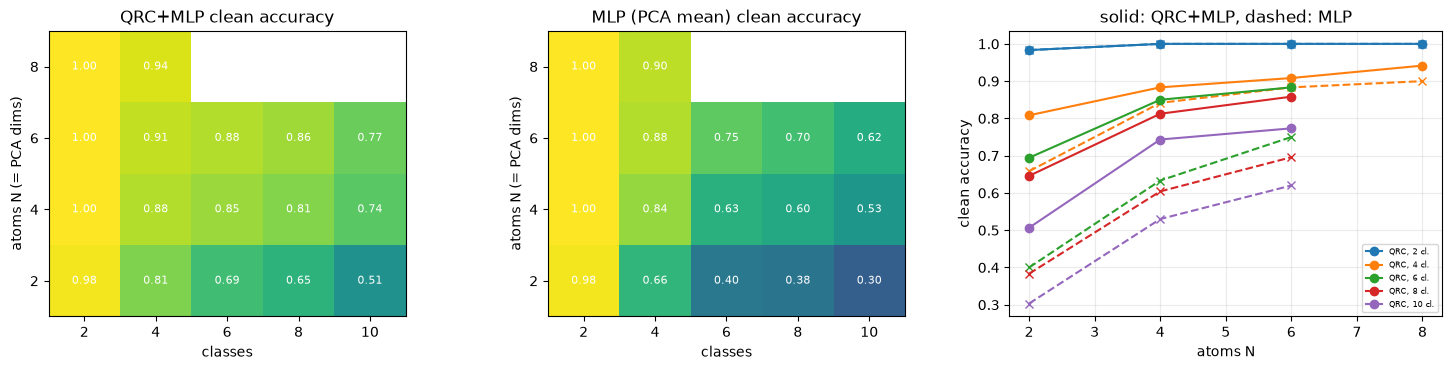

In [17]:
# ---- Fig. 1b analogue: clean accuracy of QRC+MLP (and of the PCA-mean MLP) versus number of classes and atoms (MNIST) ----
grid_rows = []; gt0 = time.time()
for atoms in GRID_ATOMS:
    for classes in GRID_CLASSES:
        if 2 ** atoms * classes > MAX_GRID_COST: continue          # cost guard, see config
        r = run_config("MNIST", atoms, classes, SEED, attack=False, models_wanted=["QRC+MLP", "MLP (PCA mean)"], tag="grid")
        grid_rows.append(dict(atoms=atoms, classes=classes, qrc=r["clean"]["QRC+MLP"], mlp=r["clean"]["MLP (PCA mean)"]))
grid = pd.DataFrame(grid_rows)
print(f"grid finished in {time.time() - gt0:.0f} s")
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, ttl in zip(axs[:2], ["qrc", "mlp"], ["QRC+MLP clean accuracy", "MLP (PCA mean) clean accuracy"]):
    piv = grid.pivot(index="atoms", columns="classes", values=col).reindex(index=list(GRID_ATOMS), columns=list(GRID_CLASSES))
    im = ax.imshow(np.ma.masked_invalid(piv.values), origin="lower", vmin=0, vmax=1, cmap="viridis")
    ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns); ax.set_yticks(range(len(piv.index))); ax.set_yticklabels(piv.index)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            if np.isfinite(piv.values[i, j]): ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
    ax.set_xlabel("classes"); ax.set_ylabel("atoms N (= PCA dims)"); ax.set_title(ttl); ax.grid(False)
for c in GRID_CLASSES:
    s = grid[grid.classes == c]; axs[2].plot(s.atoms, s.qrc, marker="o", label=f"QRC, {c} cl."); axs[2].plot(s.atoms, s.mlp, marker="x", ls="--", color=axs[2].lines[-1].get_color())
axs[2].set_xlabel("atoms N"); axs[2].set_ylabel("clean accuracy"); axs[2].set_title("solid: QRC+MLP, dashed: MLP"); axs[2].legend(fontsize=6)
plt.tight_layout(); plt.show()


### 6.2 Reservoir size N versus robustness (Figs. 3-6)
Classes = atoms = PCA dimensions = N as in the paper's Figs. 4-6. Every model is trained once and then attacked. Console lines show the clean accuracy of the five models and the time spent attacking each.


In [18]:
# ---- the main experiment: for every dataset and N in SWEEP_N: classes = atoms = PCA dims = N, all five models, clean + FGSM / PGD / DeepFool ----
sweep_t0 = time.time()
for ds in DATASETS:
    for N in SWEEP_N:
        run_config(ds, N, N, SEEDS[0], attack=True)
        print(f"  elapsed {(time.time() - sweep_t0) / 60:.1f} min")


[MNIST atoms=4 classes=4 seed=42 paper] clean test acc: QRC+MLP=0.883, MLP (PCA mean)=0.842, MLP (PCA patches)=0.942, Random tanh reservoir+MLP=0.925, MLP (64 pixels)=0.942  (41 s)


    attacked QRC+MLP                      in   41.4 s


    attacked MLP (PCA mean)               in    2.5 s


    attacked MLP (PCA patches)            in    2.8 s


    attacked Random tanh reservoir+MLP    in   42.2 s


...

    attacked QRC+MLP                      in  214.7 s


    attacked MLP (PCA mean)               in    1.6 s


    attacked MLP (PCA patches)            in    2.7 s


    attacked Random tanh reservoir+MLP    in   89.9 s


    attacked MLP (64 pixels)              in    5.4 s
    attack set: 120 test images; total 382 s
  elapsed 36.3 min


### 6.3 Clean accuracy over seeds


In [19]:
# ---- more seeds (clean accuracy only; the data draw, the split and the MLP initialisation change with the seed) ----
rows = []
for ds in DATASETS:
    for N in SWEEP_N:
        for sd in SEEDS:
            r = run_config(ds, N, N, sd, attack=False) if sd != SEEDS[0] else RESULTS[(ds, N, N, sd, "paper")]
            for m, a in r["clean"].items(): rows.append(dict(dataset=ds, N=N, seed=sd, model=m, clean=a))
sd_df = pd.DataFrame(rows)
tab = sd_df.groupby(["dataset", "N", "model"]).clean.agg(["mean", "std", "count"]).reset_index()
tab["clean accuracy"] = tab.apply(lambda r: f"{r['mean']:.3f} +- {0 if r['count'] < 2 else r['std']:.3f}", axis=1)
display(tab.pivot(index=["dataset", "N"], columns="model", values="clean accuracy")[MODEL_ORDER])


[MNIST atoms=4 classes=4 seed=43 paper] clean test acc: QRC+MLP=0.950, MLP (PCA mean)=0.858, MLP (PCA patches)=0.975, Random tanh reservoir+MLP=0.942, MLP (64 pixels)=0.983  (34 s)


[MNIST atoms=5 classes=5 seed=43 paper] clean test acc: QRC+MLP=0.920, MLP (PCA mean)=0.820, MLP (PCA patches)=0.960, Random tanh reservoir+MLP=0.920, MLP (64 pixels)=0.973  (48 s)


[MNIST atoms=6 classes=6 seed=43 paper] clean test acc: QRC+MLP=0.906, MLP (PCA mean)=0.789, MLP (PCA patches)=0.961, Random tanh reservoir+MLP=0.917, MLP (64 pixels)=0.944  (75 s)


[FashionMNIST atoms=4 classes=4 seed=43 paper] clean test acc: QRC+MLP=0.683, MLP (PCA mean)=0.642, MLP (PCA patches)=0.817, Random tanh reservoir+MLP=0.725, MLP (64 pixels)=0.892  (39 s)


[FashionMNIST atoms=5 classes=5 seed=43 paper] clean test acc: QRC+MLP=0.687, MLP (PCA mean)=0.553, MLP (PCA patches)=0.793, Random tanh reservoir+MLP=0.620, MLP (64 pixels)=0.853  (57 s)


[FashionMNIST atoms=6 classes=6 seed=43 paper] clean test acc: QRC+MLP=0.761, MLP (PCA mean)=0.600, MLP (PCA patches)=0.822, Random tanh reservoir+MLP=0.661, MLP (64 pixels)=0.861  (69 s)


[KuzushijiMNIST atoms=4 classes=4 seed=43 paper] clean test acc: QRC+MLP=0.667, MLP (PCA mean)=0.558, MLP (PCA patches)=0.850, Random tanh reservoir+MLP=0.667, MLP (64 pixels)=0.825  (32 s)


[KuzushijiMNIST atoms=5 classes=5 seed=43 paper] clean test acc: QRC+MLP=0.627, MLP (PCA mean)=0.453, MLP (PCA patches)=0.820, Random tanh reservoir+MLP=0.593, MLP (64 pixels)=0.773  (31 s)


[KuzushijiMNIST atoms=6 classes=6 seed=43 paper] clean test acc: QRC+MLP=0.683, MLP (PCA mean)=0.478, MLP (PCA patches)=0.794, Random tanh reservoir+MLP=0.628, MLP (64 pixels)=0.767  (61 s)


model                    QRC+MLP  MLP (PCA mean) MLP (PCA patches)  \
dataset        N                                                     
FashionMNIST   4  0.713 +- 0.041  0.642 +- 0.000    0.854 +- 0.053   
               5  0.697 +- 0.014  0.537 +- 0.024    0.800 +- 0.009   
               6  0.750 +- 0.016  0.611 +- 0.016    0.822 +- 0.000   
KuzushijiMNIST 4  0.721 +- 0.077  0.629 +- 0.100    0.871 +- 0.029   
               5  0.697 +- 0.099  0.513 +- 0.085    0.837 +- 0.024   
               6  0.689 +- 0.008  0.481 +- 0.004    0.794 +- 0.000   
MNIST          4  0.917 +- 0.047  0.850 +- 0.012    0.958 +- 0.024   
               5  0.927 +- 0.009  0.797 +- 0.033    0.943 +- 0.024   
               6  0.894 +- 0.016  0.769 +- 0.027    0.933 +- 0.039   

model            Random tanh reservoir+MLP MLP (64 pixels)  
dataset        N                                            
FashionMNIST   4            0.700 +- 0.035  0.896 +- 0.006  
               5            0.637 +- 0.024  0.840 +- 0.019  
               6            0.675 +- 0.020  0.847 +- 0.020  
KuzushijiMNIST 4            0.688 +- 0.029  0.875 +- 0.071  
               5            0.647 +- 0.075  0.823 +- 0.071  
               6            0.619 +- 0.012  0.792 +- 0.035  
MNIST          4            0.933 +- 0.012  0.962 +- 0.029  
               5            0.923 +- 0.005  0.957 +- 0.024  
               6            0.886 +- 0.043  0.928 +- 0.024

### 6.4 Accuracy under attack and the gain Delta Acc
Top row: mean accuracy gain `Delta Acc_N = mean_eps (Acc_QRC+MLP - Acc_MLP)` over eps > 0 (green = the reservoir helps). Bottom row: accuracy versus eps (solid QRC+MLP, dashed MLP). The last figures add the three other classical models.


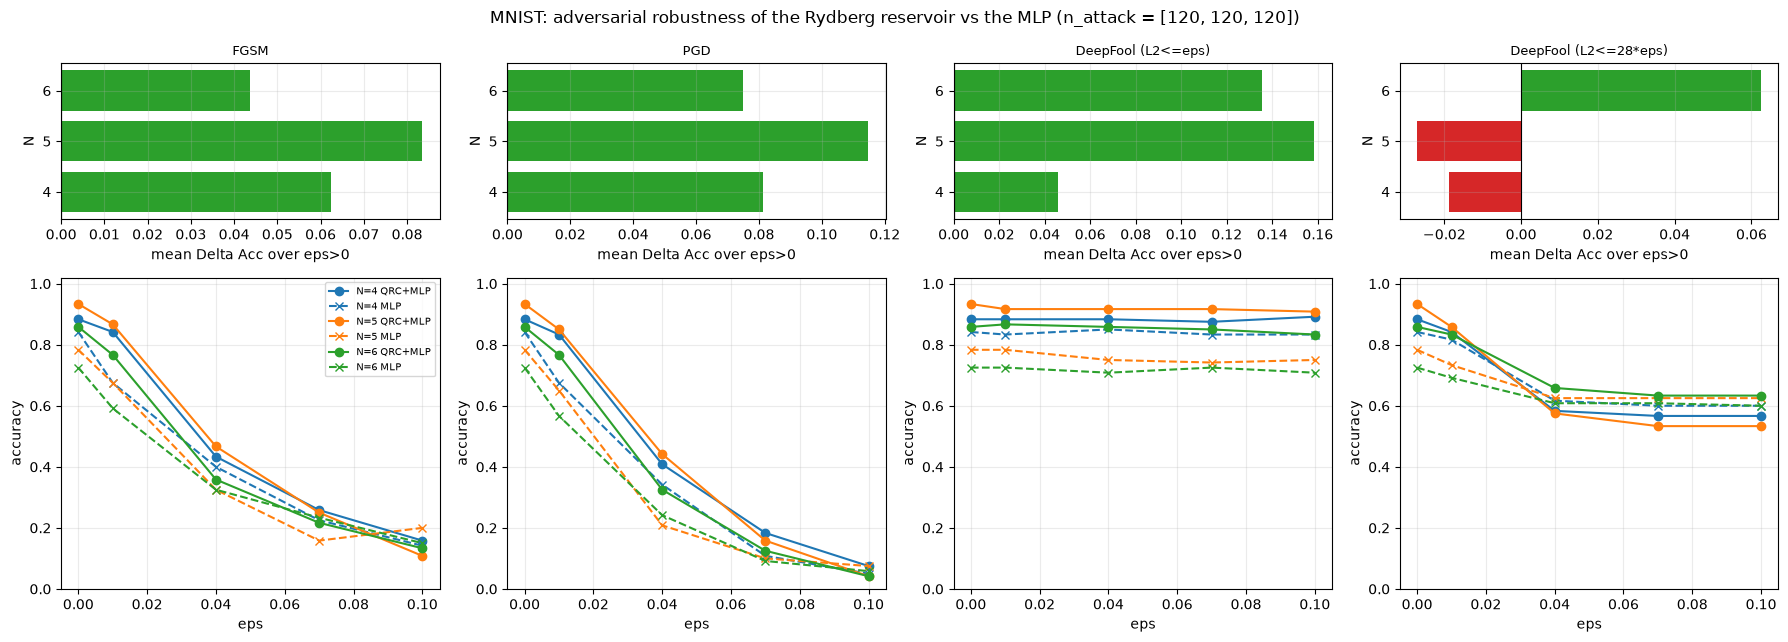

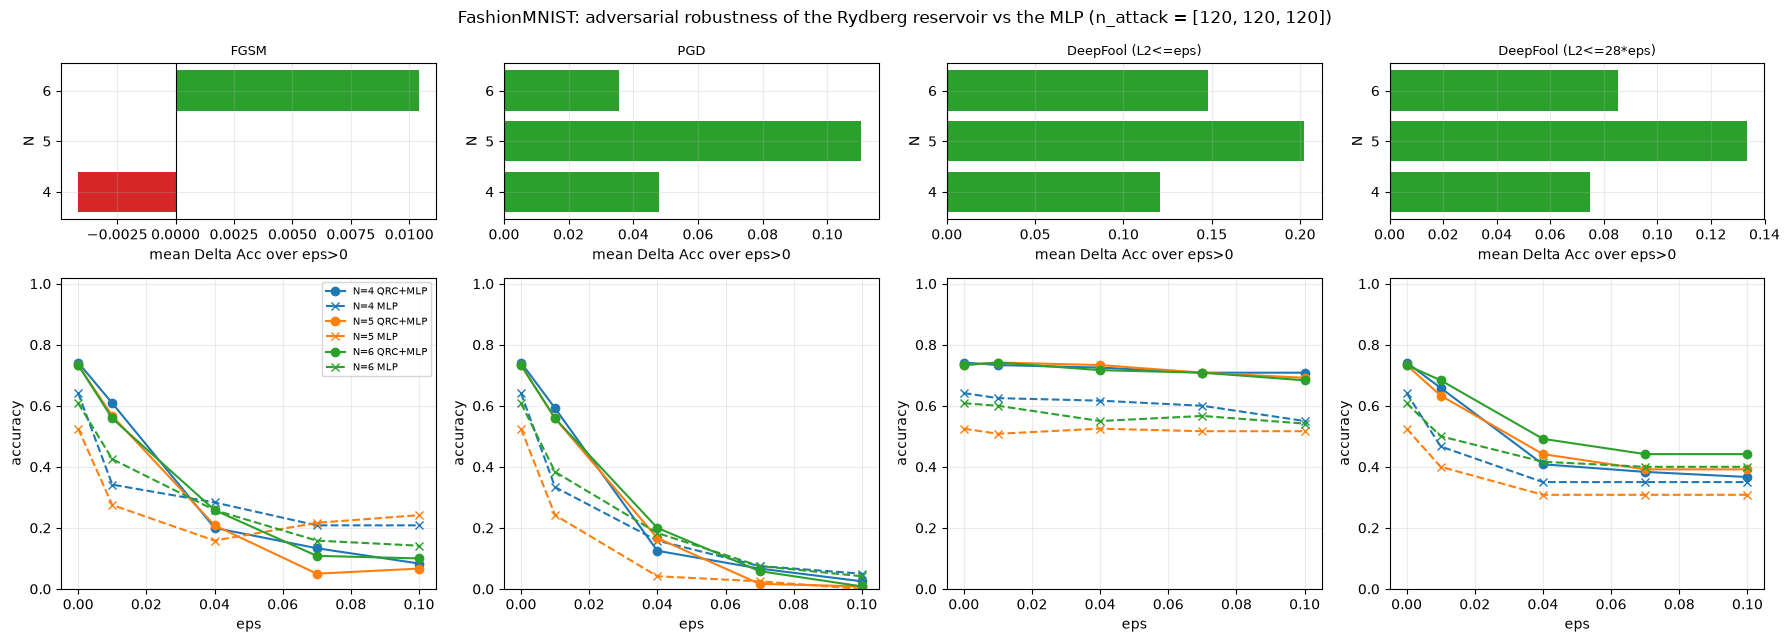

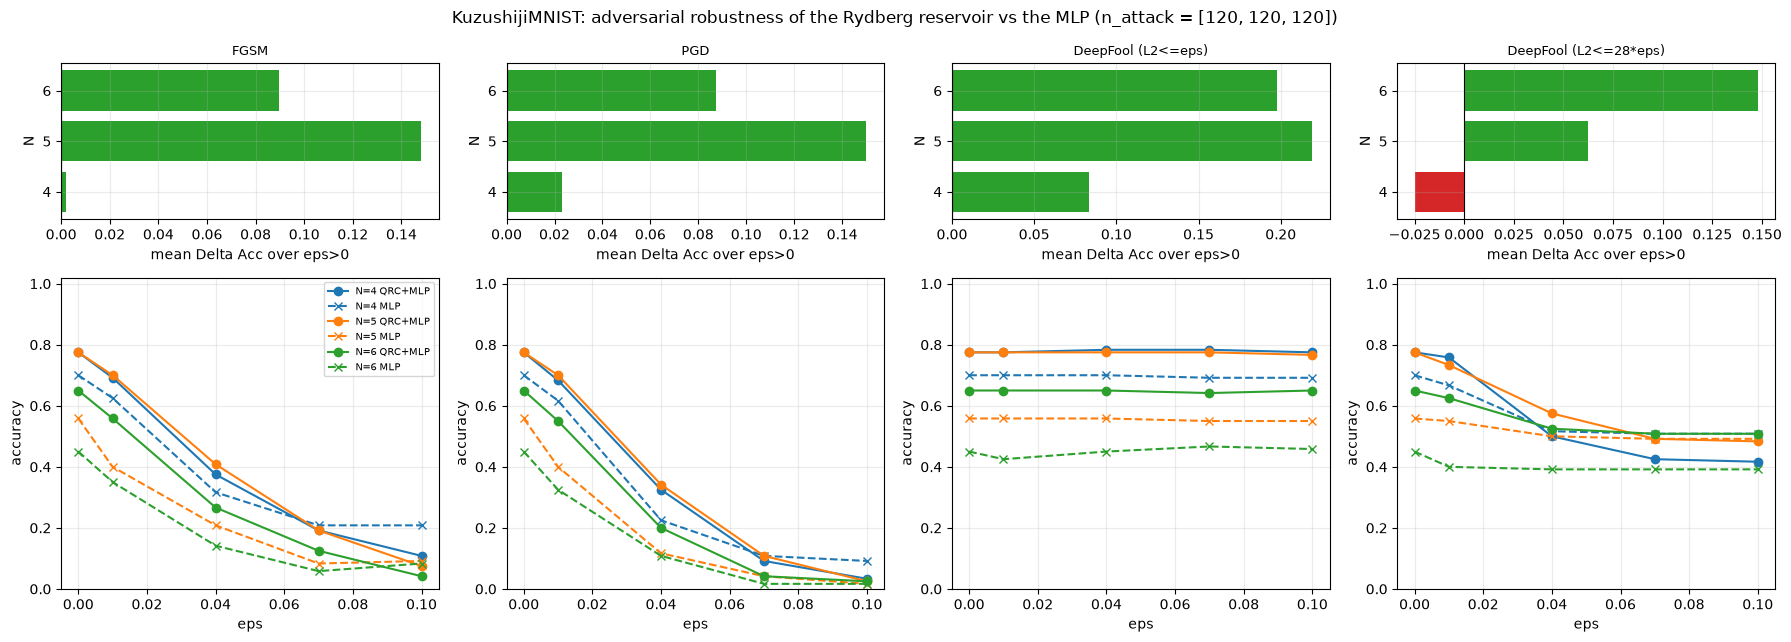

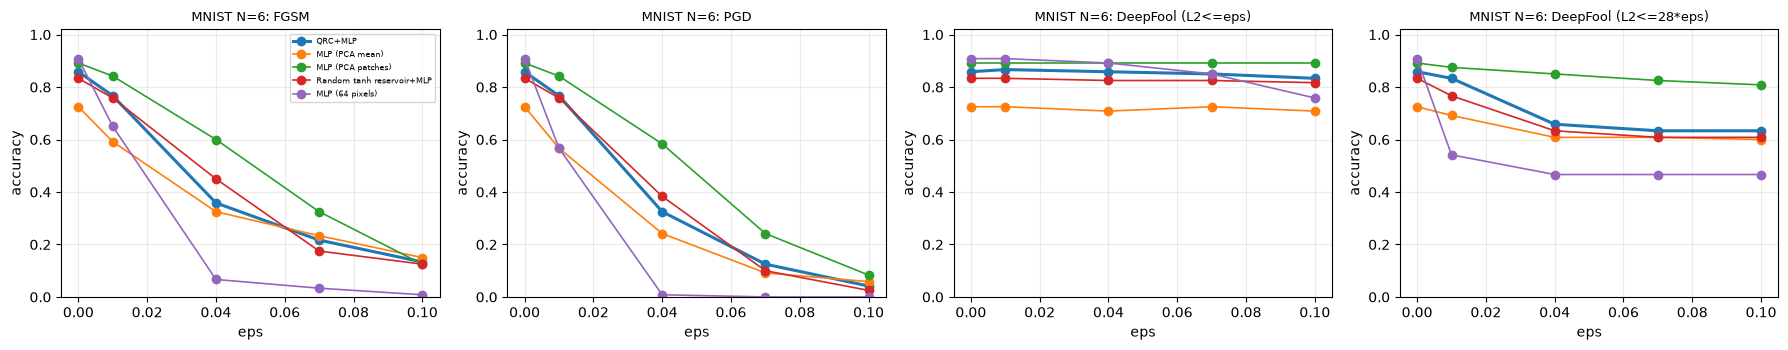

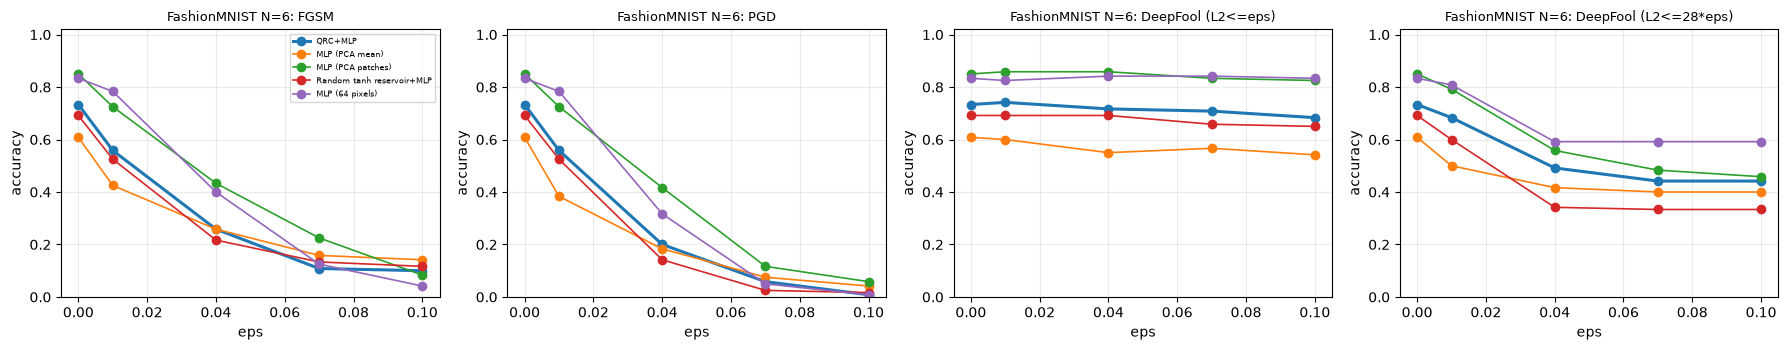

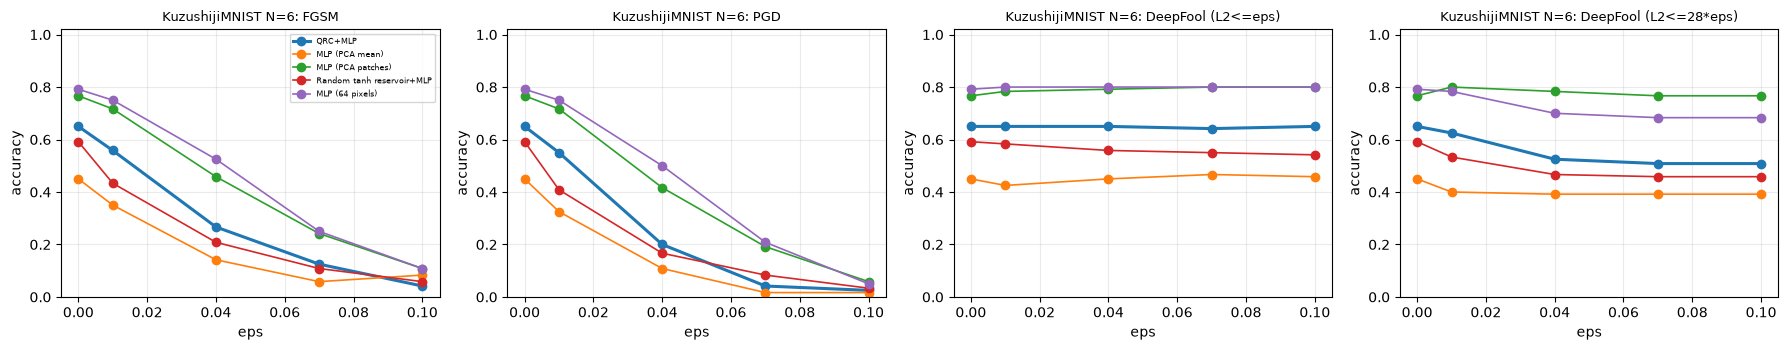

In [20]:
# ---- Figs. 4-6 analogue: accuracy versus eps (solid QRC+MLP, dashed MLP) and the mean accuracy gain Delta Acc_N (Eq. 15) ----
PRIMARY = "MLP (PCA mean)"
def delta_acc(adv, att, model="QRC+MLP", base=PRIMARY):
    q, b = np.array(adv[att][model]), np.array(adv[att][base]); return float((q - b)[1:].mean())   # E = non-zero eps of the grid

for ds in DATASETS:
    fig, axs = plt.subplots(2, 4, figsize=(18, 6.5), gridspec_kw=dict(height_ratios=[1, 2]))
    for j, att in enumerate(ATTACKS):
        Ns = [N for N in SWEEP_N]; vals = [delta_acc(RESULTS[(ds, N, N, SEEDS[0], "paper")]["adv"], att) for N in Ns]
        axs[0, j].barh([str(n) for n in Ns], vals, color=["tab:green" if v >= 0 else "tab:red" for v in vals]); axs[0, j].set_title(att, fontsize=9)
        axs[0, j].set_xlabel("mean Delta Acc over eps>0"); axs[0, j].set_ylabel("N"); axs[0, j].axvline(0, color="k", lw=0.8)
        for k, N in enumerate(Ns):
            adv = RESULTS[(ds, N, N, SEEDS[0], "paper")]["adv"][att]
            l, = axs[1, j].plot(EPS_GRID, adv["QRC+MLP"], marker="o", label=f"N={N} QRC+MLP")
            axs[1, j].plot(EPS_GRID, adv[PRIMARY], ls="--", marker="x", color=l.get_color(), label=f"N={N} MLP")
        axs[1, j].set_xlabel("eps"); axs[1, j].set_ylabel("accuracy"); axs[1, j].set_ylim(0, 1.02)
        if j == 0: axs[1, j].legend(fontsize=7)
    plt.suptitle(f"{ds}: adversarial robustness of the Rydberg reservoir vs the MLP (n_attack = {[RESULTS[(ds, N, N, SEEDS[0], 'paper')]['n_attack'] for N in SWEEP_N]})")
    plt.tight_layout(); plt.show()

# all five models, largest N
Nmax = max(SWEEP_N)
for ds in DATASETS:
    fig, axs = plt.subplots(1, 4, figsize=(18, 3.6))
    for j, att in enumerate(ATTACKS):
        adv = RESULTS[(ds, Nmax, Nmax, SEEDS[0], "paper")]["adv"][att]
        for m in MODEL_ORDER: axs[j].plot(EPS_GRID, adv[m], marker="o", label=m, lw=2.2 if m == "QRC+MLP" else 1.2)
        axs[j].set_title(f"{ds} N={Nmax}: {att}", fontsize=9); axs[j].set_xlabel("eps"); axs[j].set_ylabel("accuracy"); axs[j].set_ylim(0, 1.02)
    axs[0].legend(fontsize=6); plt.tight_layout(); plt.show()


In [21]:
# ---- numbers behind the figures ----
rows = []
for ds in DATASETS:
    for N in SWEEP_N:
        r = RESULTS[(ds, N, N, SEEDS[0], "paper")]
        for att in ATTACKS:
            for m in MODEL_ORDER:
                rows.append(dict(dataset=ds, N=N, attack=att, model=m, n_attack=r["n_attack"], **{f"eps={e}": a for e, a in zip(EPS_GRID, r["adv"][att][m])}))
ADV_DF = pd.DataFrame(rows)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
show = ADV_DF[ADV_DF.N == max(SWEEP_N)]
display(show[show.attack.isin(["FGSM", "PGD"])].round(3).reset_index(drop=True))


,dataset,N,attack,model,n_attack,eps=0.0,eps=0.01,eps=0.04,eps=0.07,eps=0.1
0,MNIST,6,FGSM,QRC+MLP,120,0.858,0.767,0.358,0.217,0.133
1,MNIST,6,FGSM,MLP (PCA mean),120,0.725,0.592,0.325,0.233,0.150
2,MNIST,6,FGSM,MLP (PCA patches),120,0.892,0.842,0.600,0.325,0.125
3,MNIST,6,FGSM,Random tanh reservoir+MLP,120,0.833,0.758,0.450,0.175,0.125
4,MNIST,6,FGSM,MLP (64 pixels),120,0.908,0.650,0.067,0.033,0.008
5,MNIST,6,PGD,QRC+MLP,120,0.858,0.767,0.325,0.125,0.042
6,MNIST,6,PGD,MLP (PCA mean),120,0.725,0.567,0.242,0.092,0.058
7,MNIST,6,PGD,MLP (PCA patches),120,0.892,0.842,0.583,0.242,0.083
8,MNIST,6,PGD,Random tanh reservoir+MLP,120,0.833,0.758,0.383,0.100,0.025
9,MNIST,6,PGD,MLP (64 pixels),120,0.908,0.567,0.008,0.000,0.000


### 6.5 Ablation: does the atom-atom interaction matter?
The paper concludes that "Rydberg interactions play a decisive role". With Table 1's constants the interaction is negligible (section 3.2), so the reservoir is effectively N independent two-level atoms
driven by a common field (a product-state "reservoir" whose `<Z_i Z_j>` features are products of the `<Z_i>`). We retrain and attack the QRC+MLP with (a) no interaction at all, (b) the paper's constants,
(c) a physical Rb C6 at 10 um and (d) a physical C6 at 5 um (inside the blockade radius).


[MNIST atoms=6 classes=6 seed=42 abl0] clean test acc: QRC+MLP=0.889  (27 s)


    attacked QRC+MLP                      in  126.6 s
    attack set: 120 test images; total 154 s


[MNIST atoms=6 classes=6 seed=42 abl1] clean test acc: QRC+MLP=0.883  (20 s)


    attacked QRC+MLP                      in  142.2 s
    attack set: 120 test images; total 162 s


[MNIST atoms=6 classes=6 seed=42 abl2] clean test acc: QRC+MLP=0.900  (28 s)


    attacked QRC+MLP                      in  133.8 s
    attack set: 120 test images; total 162 s


[MNIST atoms=6 classes=6 seed=42 abl3] clean test acc: QRC+MLP=0.850  (29 s)


    attacked QRC+MLP                      in  156.0 s
    attack set: 120 test images; total 185 s


,reservoir,clean,FGSM eps=0.01,FGSM eps=0.04,FGSM eps=0.07,FGSM eps=0.1,PGD eps=0.01,PGD eps=0.04,PGD eps=0.07,PGD eps=0.1
0,C6=0 (no interaction),0.889,0.783,0.367,0.225,0.142,0.783,0.325,0.142,0.033
1,"paper (C6=2pi*2000, d=10 um)",0.883,0.767,0.358,0.217,0.133,0.767,0.325,0.125,0.042
2,"Rb C6, d=10 um",0.900,0.817,0.475,0.242,0.117,0.817,0.425,0.175,0.033
3,"Rb C6, d=5 um (blockade)",0.850,0.708,0.417,0.258,0.142,0.708,0.308,0.058,0.025


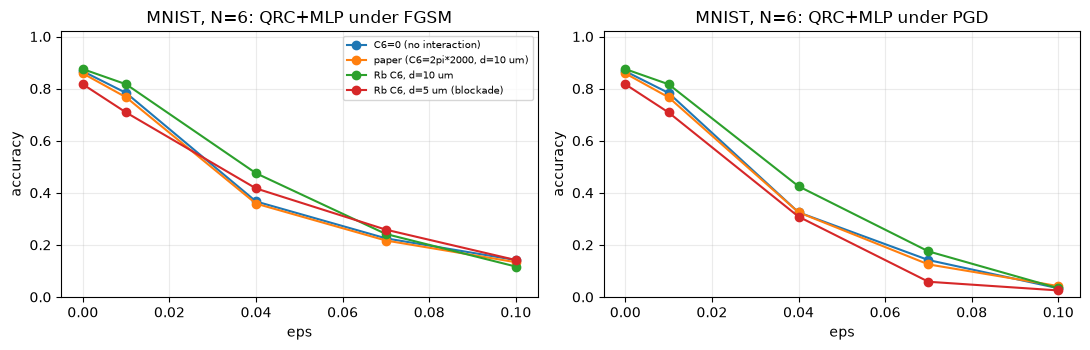

In [22]:
# ---- ablation: does the Rydberg interaction matter?  (paper: "Rydberg interactions play a decisive role in shaping adversarial robustness") ----
ABL = {"C6=0 (no interaction)": dict(C6=0.0), "paper (C6=2pi*2000, d=10 um)": dict(),
       "Rb C6, d=10 um": dict(C6=C6_RB), "Rb C6, d=5 um (blockade)": dict(C6=C6_RB, d_um=5.0)}
abl_rows, abl_curves = [], {}
for i, (name, kw) in enumerate(ABL.items()):
    r = run_config("MNIST", ABLATION_N, ABLATION_N, SEEDS[0], attack=True, models_wanted=["QRC+MLP"], res_kw=kw, attacks=("FGSM", "PGD"), tag=f"abl{i}")
    abl_curves[name] = r["adv"]
    abl_rows.append(dict(reservoir=name, clean=r["clean"]["QRC+MLP"], **{f"FGSM eps={e}": a for e, a in zip(EPS_GRID[1:], r["adv"]["FGSM"]["QRC+MLP"][1:])},
                         **{f"PGD eps={e}": a for e, a in zip(EPS_GRID[1:], r["adv"]["PGD"]["QRC+MLP"][1:])}))
ABL_DF = pd.DataFrame(abl_rows); display(ABL_DF.round(3))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for j, att in enumerate(("FGSM", "PGD")):
    for name in ABL: axs[j].plot(EPS_GRID, abl_curves[name][att]["QRC+MLP"], marker="o", label=name)
    axs[j].set_title(f"MNIST, N={ABLATION_N}: QRC+MLP under {att}"); axs[j].set_xlabel("eps"); axs[j].set_ylabel("accuracy"); axs[j].set_ylim(0, 1.02)
axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()


## 7. Side-by-side comparison with the paper

*reproduced* = the statement holds in this notebook; *not reached* / *exceeded* = it does not (the counts say how far); *cannot be checked* = the paper prints no number. All paper statements concern line and bar plots,
so they are tested as orderings and trends over all (dataset, N, eps) cells, with the mean accuracy gain reported next to them. The attacked sets are small (see `n_attack`), so single cells carry a binomial noise of several points; the "every cell" criterion of the paper is
therefore a strict test that a real but small effect can fail by chance.


In [23]:
# ---- side by side with the paper: one verdict per checkable claim ----
# The paper gives NO accuracy table: all results are line plots and bar charts. Claims are therefore tested as statements (orderings, trends),
# and the only numbers read off the paper are the upper ends of the Delta-Acc axes of Figs. 4-6 (indicative bounds, not measured values).
CL = []
def add(claim, paper, ours, verdict): CL.append({"claim": claim, "paper": paper, "this notebook": ours, "verdict": verdict})

def cells(attack, base=PRIMARY, model="QRC+MLP"):
    out = []
    for ds in DATASETS:
        for N in SWEEP_N:
            a = RESULTS[(ds, N, N, SEEDS[0], "paper")]["adv"][attack]
            for e, q, b in zip(EPS_GRID[1:], a[model][1:], a[base][1:]): out.append((ds, N, e, q, b))
    return out

# 1. clean accuracy increases with the reservoir size (Fig. 1b)
steps = []
for c in GRID_CLASSES:
    s = grid[grid.classes == c].sort_values("atoms"); steps += [(b - a) >= -0.01 for a, b in zip(s.qrc[:-1], s.qrc[1:])]
frac = float(np.mean(steps))
add("Clean accuracy of QRC+MLP grows with the number of atoms (Fig. 1b, Discussion)", "\"larger reservoirs consistently achieved higher clean accuracies\"",
    f"{int(sum(steps))}/{len(steps)} atom increments non-decreasing (tol 1 pt)", "reproduced" if frac >= 0.8 else f"not reached ({frac:.0%} of increments)")

# 2. hybrid clean accuracy > MLP
n_hi = sum(RESULTS[(ds, N, N, SEEDS[0], "paper")]["clean"]["QRC+MLP"] > RESULTS[(ds, N, N, SEEDS[0], "paper")]["clean"][PRIMARY] for ds in DATASETS for N in SWEEP_N)
add("QRC+MLP has higher clean accuracy than the MLP on the same compressed features (abstract)", "higher in every setting",
    f"{n_hi}/{len(DATASETS) * len(SWEEP_N)} (dataset, N) settings", "reproduced" if n_hi == len(DATASETS) * len(SWEEP_N) else f"not reached ({n_hi}/{len(DATASETS) * len(SWEEP_N)})")

# 3-6. adversarial: QRC+MLP above the MLP at every eps
for att in ATTACKS:
    cs = cells(att); wins = sum(q > b for *_, q, b in cs); ties = sum(q == b for *_, q, b in cs); dm = np.mean([q - b for *_, q, b in cs])
    verdict = "reproduced" if wins == len(cs) else (f"not reached ({wins}/{len(cs)} strictly above, {ties} ties)")
    if att.startswith("DeepFool (L2<=eps)") and ties > 0.5 * len(cs): verdict += "; attack too weak to discriminate"
    add(f"Under {att}, QRC+MLP stays above the MLP at every eps in (0, 0.1] (Figs. 3-6)", "above in all settings",
        f"{wins}/{len(cs)} (dataset, N, eps) cells above; mean Delta Acc = {dm:+.3f}", verdict)

# 7. the same against the stronger / fairer classical controls
for base in ["MLP (PCA patches)", "Random tanh reservoir+MLP", "MLP (64 pixels)"]:
    for att in ("FGSM", "PGD"):
        cs = cells(att, base=base); wins = sum(q > b for *_, q, b in cs); dm = np.mean([q - b for *_, q, b in cs])
        add(f"(extra control, not in the paper) QRC+MLP above {base} under {att}", "not tested in the paper",
            f"{wins}/{len(cs)} cells above; mean Delta Acc = {dm:+.3f}", "reproduced" if wins == len(cs) else f"not reached ({wins}/{len(cs)})")

# 8. Delta Acc grows with N (Figs. 4-6, Discussion)
if len(SWEEP_N) > 1:
    for att in ("FGSM", "PGD"):
        ok = []
        for ds in DATASETS:
            d = [delta_acc(RESULTS[(ds, N, N, SEEDS[0], "paper")]["adv"], att) for N in SWEEP_N]; ok.append(d[-1] > d[0])
        add(f"Mean Delta Acc under {att} is larger for the largest N than for the smallest N", "increases with N",
            f"{sum(ok)}/{len(ok)} datasets; Delta Acc(N): " + "; ".join(f"{ds}: " + ", ".join(f"{delta_acc(RESULTS[(ds, N, N, SEEDS[0], 'paper')]['adv'], att):+.3f}" for N in SWEEP_N) for ds in DATASETS),
            "reproduced" if all(ok) else f"not reached ({sum(ok)}/{len(ok)})")

# 9. magnitude: paper axis maxima of the Delta-Acc bar charts (indicative upper bounds)
AX = {"MNIST": {"FGSM": 0.07, "PGD": 0.10, "DeepFool (L2<=28*eps)": 0.40}, "FashionMNIST": {"FGSM": 0.13, "PGD": 0.15, "DeepFool (L2<=28*eps)": 0.30},
      "KuzushijiMNIST": {"FGSM": 0.08, "PGD": 0.13, "DeepFool (L2<=28*eps)": 0.24}}
for ds in DATASETS:
    for att, mx in AX[ds].items():
        d = max(delta_acc(RESULTS[(ds, N, N, SEEDS[0], "paper")]["adv"], att) for N in SWEEP_N)
        add(f"Size of the gain: largest mean Delta Acc of {ds} under {att}", f"bar-axis maximum {mx:.2f} (read from Fig. {dict(MNIST=4, FashionMNIST=5, KuzushijiMNIST=6)[ds]})",
            f"{d:+.3f}", "reproduced" if 0 < d <= 1.2 * mx else ("exceeded" if d > 1.2 * mx else "not reached (no positive gain)") + f" (ours {d:+.3f})")

# 10. interactions
ref = ABL_DF.set_index("reservoir")
cols = [c for c in ref.columns if c.startswith(("clean", "FGSM", "PGD"))]
diff = (ref.loc["paper (C6=2pi*2000, d=10 um)", cols] - ref.loc["C6=0 (no interaction)", cols]).abs().max()
diff_strong = (ref.loc["Rb C6, d=5 um (blockade)", cols] - ref.loc["C6=0 (no interaction)", cols]).abs().max()
add("The interaction V_ij of Table 1 is what shapes robustness (\"Rydberg interactions play a decisive role\")", "decisive role",
    f"max |accuracy difference| to the interaction-free reservoir: {diff:.3f} with the paper's C6; {diff_strong:.3f} with physical C6 at 5 um",
    "reproduced" if diff > 0.05 else f"not reached (paper constants are indistinguishable from V=0: max diff {diff:.3f})")

# 11. absolute numbers
add("Absolute accuracies in Figs. 1b, 3-6", "plots only, no printed values", "see tables above", "cannot be checked")
add("Hamiltonian / pipeline parameters of Table 1 and 'D = M (N + N(N-1)/2)'", "N=8, M=6: D = 216", f"D = {get_reservoir(8).D}", "reproduced" if get_reservoir(8).D == 216 else "not reached")
add("Hybrid beats \"purely classical models across all perturbation strengths\" (abstract) - tested against all four classical models", "all strengths",
    "see the five-model tables: QRC+MLP vs best classical per cell", "see rows above")
VERDICT_DF = pd.DataFrame(CL)
pd.set_option("display.max_colwidth", 140)
display(VERDICT_DF.style.set_properties(**{"text-align": "left"}))
print(VERDICT_DF.verdict.str.split(" ").str[0].value_counts().to_string())


,claim,paper,this notebook,verdict
0,"Clean accuracy of QRC+MLP grows with the number of atoms (Fig. 1b, Discussion)","""larger reservoirs consistently achieved higher clean accuracies""",12/12 atom increments non-decreasing (tol 1 pt),reproduced
1,QRC+MLP has higher clean accuracy than the MLP on the same compressed features (abstract),higher in every setting,"9/9 (dataset, N) settings",reproduced
2,"Under FGSM, QRC+MLP stays above the MLP at every eps in (0, 0.1] (Figs. 3-6)",above in all settings,"21/36 (dataset, N, eps) cells above; mean Delta Acc = +0.048","not reached (21/36 strictly above, 1 ties)"
3,"Under PGD, QRC+MLP stays above the MLP at every eps in (0, 0.1] (Figs. 3-6)",above in all settings,"26/36 (dataset, N, eps) cells above; mean Delta Acc = +0.081","not reached (26/36 strictly above, 0 ties)"
4,"Under DeepFool (L2<=eps), QRC+MLP stays above the MLP at every eps in (0, 0.1] (Figs. 3-6)",above in all settings,"36/36 (dataset, N, eps) cells above; mean Delta Acc = +0.146",reproduced
5,"Under DeepFool (L2<=28*eps), QRC+MLP stays above the MLP at every eps in (0, 0.1] (Figs. 3-6)",above in all settings,"25/36 (dataset, N, eps) cells above; mean Delta Acc = +0.055","not reached (25/36 strictly above, 1 ties)"
6,"(extra control, not in the paper) QRC+MLP above MLP (PCA patches) under FGSM",not tested in the paper,3/36 cells above; mean Delta Acc = -0.120,not reached (3/36)
7,"(extra control, not in the paper) QRC+MLP above MLP (PCA patches) under PGD",not tested in the paper,0/36 cells above; mean Delta Acc = -0.136,not reached (0/36)
8,"(extra control, not in the paper) QRC+MLP above Random tanh reservoir+MLP under FGSM",not tested in the paper,18/36 cells above; mean Delta Acc = +0.009,not reached (18/36)
9,"(extra control, not in the paper) QRC+MLP above Random tanh reservoir+MLP under PGD",not tested in the paper,19/36 cells above; mean Delta Acc = +0.014,not reached (19/36)


verdict
reproduced    12
not           12
exceeded       1
cannot         1
see            1


## 8. Reading the paper critically

﻿(Written after the full run; numbers are from the tables above, seed 42, single runs on small attacked sets, so individual cells can move with another seed.)

**What the run found.** Of the 27 rows of the verdict table, 12 are *reproduced*, 12 *not reached*, 1 *exceeded*, 1 *cannot be checked* and 1 is a pointer to the five-model tables. The paper's qualitative picture partly holds: the reservoir features give a clearly higher clean accuracy than the same MLP on the N compressed features (9 of 9 settings; for example MNIST, 6 atoms and classes: 0.88 vs 0.75, Fashion-MNIST 0.74 vs 0.62, Kuzushiji 0.69 vs 0.48), clean accuracy grows with the number of atoms in all 12 steps of the Fig. 1b grid (10 classes: 0.51, 0.74, 0.77 for 2, 4, 6 atoms), and the mean accuracy gain Delta Acc is positive on average for FGSM (+0.05), PGD (+0.08) and the RMS-matched DeepFool (+0.06). But "above the MLP at every eps" fails in 15 of 36 cells for FGSM and 10 of 36 for PGD, and Delta Acc does not grow with N (it peaks at N = 5 for all three datasets under PGD).

**1. The comparison baseline is weak, and the gain mostly mirrors the clean-accuracy gap.** The "MLP" that the reservoir beats sees one number per atom after the four patches are *averaged*, which discards almost all spatial information (patch-averaging a linear projection is a projection of the mean patch). The reservoir applies a nonlinear map *before* averaging, so it keeps more of the image. Three controls that the paper does not run show this: an MLP on all 4 x N PCA features is better than QRC+MLP in clean accuracy on every dataset at N = 6 (0.91 vs 0.88 on MNIST; at N = 5 on MNIST the two are level) and under attack (QRC above it in 3 of 36 FGSM and 0 of 36 PGD cells, mean Delta Acc -0.12 and -0.14); an MLP on the 64 pixels is about as good as QRC+MLP under attack (mean Delta Acc -0.03); and a *random classical tanh reservoir* with exactly the same output size D is statistically indistinguishable from the Rydberg reservoir (mean Delta Acc +0.01, QRC above it in 18 of 36 FGSM and 19 of 36 PGD cells, but the random reservoir is clearly worse in clean accuracy on Fashion-MNIST and Kuzushiji, e.g. 0.69 vs 0.74 and 0.61 vs 0.69 at N = 6). So what the data support is "a fixed nonlinear feature expansion before the patch average helps a very thin classifier", not a quantum-specific robustness advantage. The paper's own caveat (Introduction) that reservoir-type models may be classically simulable is, in this experiment, literally true: we simulate it exactly in NumPy.

**2. With Table 1's constants the atoms do not interact.** `V_nn = C6/d^6 = 2pi x 0.002 MHz`, 4e-4 of the Rabi frequency, a blockade radius of 2.7 um against a 10 um spacing. The connected correlations `<ZiZj> - <Zi><Zj>` are numerically negligible (section 3.2), so the reservoir is N independent single atoms, a product state, and the `<ZiZj>` features are products of the `<Zi>`. The ablation agrees: the paper's constants and C6 = 0 differ by at most 0.017 in accuracy (below the binomial noise of 120 attacked images, about 0.045), so the claim that "Rydberg interactions play a decisive role" is *not reached*; with a physical rubidium C6 at 5 um the accuracies move by up to 0.08, but not in a consistent direction, so this too is within noise. Possible causes are a unit slip in Table 1 (C6 of order 2pi x 10^6 MHz um^6 is physical) or a different effective lattice in the CUDA-Q code; the paper's code is not available to decide.

**3. Attack design drives the numbers.** (a) DeepFool with an L2 budget of eps <= 0.1 on a 784-pixel image (about 0.004 per pixel) leaves every model at its clean accuracy (flat curves), so its "36 of 36 cells above" simply restates the clean-accuracy gap and says nothing about robustness; we therefore also report the budget 28 eps. (b) DeepFool is a minimum-norm attack, so the curves saturate once the budget exceeds the distance to the decision boundary (all curves plateau at 0.5-0.65 for 28 eps >= 1.1). (c) Our PGD uses 3 to 5 steps with a random start (the paper: 100 steps of size 1e-3); at eps = 0.1 almost every model is at or below about 15 % with FGSM and PGD alike, where differences between models vanish. (d) The attacks are white box through the exact Jacobian, so there is no gradient masking from sampling noise (the paper's analogue hardware would have shot noise, which is not studied). (e) Only 120 images are attacked at N <= 6 (a binomial standard error of 0.03-0.045 per accuracy), 48 or fewer at larger N, and one seed; the gaps in many cells are of this size.

**4. What could not be tested.** N = 8 and 10 atoms under attack (the paper's Table 1 has N = 8) need an exact Jacobian of a 256- or 1024-dimensional evolution for every image, patch and attack step; at N = 8 the clean accuracy is available (0.94 with 4 classes, one seed) but no attacks. The paper's absolute accuracies, the 100-step PGD, its sample indices and its hardware-noise discussion are not checkable. The paper's data-set sentence "700 samples for 10 classes" contradicts "100 per class"; we used 100 per class.

**5. Digital versus analogue.** The Trotter circuit confirms that the reservoir *can* be run on a gate-based machine, but not cheaply: with `Omega = 2pi x 5 MHz` and 0.5 us between read-outs, one needs roughly 32 Strang steps per interval (a circuit depth of several thousand layers for the last read-out of an 8-atom chain, 28 two-qubit gates per step) to reach an error of 0.02 in the features. That cost, not accuracy, is the practical argument for analogue hardware, and it also means a digital implementation would not be "shallow" at all.




## 9. Exercises

1. **Turn the interaction on.** Re-run section 6.5 with `d_um` = 4, 6 and 8 um and the physical C6. Does accuracy under PGD change monotonically with the interaction strength?
2. **Match the baseline.** Increase the width of "MLP (PCA patches)" or use the random reservoir with D = 1000 tanh features. Does the quantum reservoir still beat the strongest classical model under PGD?
3. **A stronger attack.** Set `PGD_STEPS = 20` for N = 4 (cheap) and compare with 5 steps. Which models lose most? Is there evidence of gradient masking (accuracy falling with more steps)?
4. **Another encoding.** Replace `to_detuning` by a random linear map of the N PCA components plus a time-dependent Omega(t) (two values per snapshot). Does robustness depend on the encoding more than on the interaction?
5. **Trotter step.** In the circuit section find the smallest number of Strang steps per interval for which the circuit-based embedding gives the same MLP accuracy as the exact one. How does that compare with `Omega dt`?
